# Smart Waste Recognition AI

## Problem Statement
Manual waste sorting can be time-consuming and inefficient. This project explores how deep learning can automatically recognise and classify waste images into different categories.

## Objective
To build and evaluate deep learning models for waste recognition, compare CNN and Vision Transformer (ViT) performance, and explore real-time recognition for automated waste sorting.

## Dataset
RealWaste, Multiclass image classification

## Table of content
1. Imports and Configurations
2. Dataset Inspection and Verification
3. Identify and Seperate Feature (X) and Target (y)
4. Dataset Splitting for Train,Test and Validation
5. Image Transformation, Preprocessing and Dataloader
6. Build a CNN from Scratch Model 1
7. Build, Train, Validate, Test, Evaluate and Compare CNN from Scratch Model 2
8. Build, Train, Validate, Test, Evaluate and Compare CNN from Scratch Model 3
9. Improve, Train, Validate, Test, Evaluate and Compare CNN  Model 3
10.  Fine-Tune Improved CNN Model 3, Train, Validate, Test, Evaluate, Compare and Select the Final Model
11. Real-Time Computer Vision and Waste Classification Using OpenCV
12. Live Capture Experiment
13. Deployment, and Documentation


## 1. Imports and Configuration

In [1]:
from google.colab import drive
import os
# Mount Google Drive
drive.mount('/content/drive')
# Create a folder to store CNN model checkpoints
CHECKPOINT_DIR = '/content/drive/MyDrive/Smart Waste Recognition AI/colab_models'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
# Define checkpoint paths
MODEL1_PATH = os.path.join(CHECKPOINT_DIR, 'cnn_model1.pth')
MODEL2_PATH = os.path.join(CHECKPOINT_DIR, 'cnn_model2.pth')
MODEL3_PATH = os.path.join(CHECKPOINT_DIR, 'cnn_model3.pth')
MODEL3_Impro_PATH = os.path.join(CHECKPOINT_DIR, 'cnn_model3_imp.pth')
MODEL3_Fine_PATH = os.path.join(CHECKPOINT_DIR, 'cnn_model3_fine.pth')



import os # importing our operating system to check our dataset files location
import pandas as pd
import numpy as np
from PIL import Image # importing Python Imaging Library PIL to open and inspect image files in python
import matplotlib.pyplot as plt
import seaborn as sns
import random #Import random for configuraton, to make every results and output reproducible
random.seed(42)        # Controls Python random numbers and ensure same output on every run
np.random.seed(42)     # Controls NumPy random numbers and ensure same output on every run
import hashlib # Import hashlib to generate  hash id ,digital fingerprints for checking duplicate images
import torch # the main PyTorch library for building and training deep learning models.
import torchvision ## provides tools for working with images and computer vision.
from torchvision import datasets #Lets us load Realwaste dataset, images using ImageFolder
torch.manual_seed(42)  # Controls PyTorch random numbers and ensure same output on every run
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)  # Set random seed for all CUDA devices
torch.backends.cudnn.deterministic = True  # Enable deterministic CUDA operations
torch.backends.cudnn.benchmark = False  # Disable automatic algorithm benchmarking
from sklearn.model_selection import train_test_split # from sklearn, import ther function to use to split the data
from torchvision import transforms # We used transforms tools in touchvision lib to prepare our image for resize, convert to tensor and normalize
from torch.utils.data import Dataset # a tool from PyTorch that helps us organise data so a model can access it one item at a time.
from torch.utils.data import DataLoader #DataLoader to deliver dataset or all images to the model in batches size rather than one image at a time.
import torch.nn as nn #imports PyTorch Neural Network  tools alias as nn,to make use of the cnn model (Conv2d)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score #Import evaluation metrics, the 4 metrics are (accuracy_score, classification_report, confusion_matrix, roc_auc_score)
import copy # Import copy for creating independent copies of model weights and objects
import cv2 # Import OpenCV for real-time image capture and processing
import base64 # Import base64 for decoding webcam-image data into computer undertandingn (pixels,rgb)
from IPython.display import display, Javascript #Import display utilities for showing the webcam image in Colab
from google.colab.output import eval_js #Import eval_js to execute JavaScript and return webcam image data to Python
import shutil # Import shutil for copying files

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


We will inspect and verify dataset attributes, metadata and ensure consistency and integrity , we want to make sure all images in every folder are consistent, find their paths and get ready for further processing


In [2]:
# importing our operating system to check our dataset files location
import os

In [3]:
# Show the folders available in the mount Colab files
print(os.listdir("//content/drive/MyDrive/Smart Waste Recognition AI"))

['RealWaste', 'plastic_prediction.jpg', '.ipynb_checkpoints', 'colab_models', 'deployment', '     Smart_Waste_Recognition _AI.ipynb']


In [4]:
# wrapping the dataset into a variable called dataset
dataset = "//content/drive/MyDrive/Smart Waste Recognition AI/RealWaste"
os.listdir(dataset)

['Vegetation',
 'Textile Trash',
 'Plastic',
 'Miscellaneous Trash',
 'Metal',
 'Paper',
 'Food Organics',
 'Cardboard',
 'Glass']

In [5]:
# looping through the dataset to count it length|shape using category, stores the current folder's name,
for category in os.listdir(dataset):
    #stores the full path to that folder,
    category_image = os.path.join(dataset, category)
    #stores a list of filenames inside that folder
    all_images = os.listdir(category_image)
# print the count on each folder that contain dataset image
    print(category, ":", len(all_images))


Vegetation : 436
Textile Trash : 318
Plastic : 921
Miscellaneous Trash : 495
Metal : 790
Paper : 500
Food Organics : 411
Cardboard : 461
Glass : 420


In [6]:
# whats the total count of all the image in dataset realwaste using the sum of earlier len output
print("Total Image:", sum([436, 318, 921, 495, 790, 500, 411, 461, 420]))

Total Image: 4752


In [7]:
import pandas as pd
import numpy as np

In [8]:
# using pd data frame, show the value in each folder in realwaste dataset, (exmaining image extension too .jpeg)
# Store all image filenames, organized by category
filenames_df = pd.DataFrame({
    category: pd.Series(os.listdir(os.path.join(dataset, category)))
    for category in os.listdir(dataset)
})

# Display the filenames on the first 100
# NoteL: 921 row is the highest len in realwaste dataset under plastic folder so our pd df row has 921
# while others not upto same lenght will be filled with NaN ( it not actual missing values, just a placeholder )
filenames_df

,Vegetation,Textile Trash,Plastic,Miscellaneous Trash,Metal,Paper,Food Organics,Cardboard,Glass
0,Vegetation_1.jpg,Textile Trash_1.jpg,Plastic_1.jpg,Miscellaneous Trash_1.jpg,Metal_1.jpg,Paper_1.jpg,Food Organics_1.jpg,Cardboard_1.jpg,Glass_1.jpg
1,Vegetation_10.jpg,Textile Trash_10.jpg,Plastic_10.jpg,Miscellaneous Trash_10.jpg,Metal_10.jpg,Paper_10.jpg,Food Organics_10.jpg,Cardboard_10.jpg,Glass_10.jpg
2,Vegetation_100.jpg,Textile Trash_100.jpg,Plastic_100.jpg,Miscellaneous Trash_100.jpg,Metal_100.jpg,Paper_100.jpg,Food Organics_100.jpg,Cardboard_100.jpg,Glass_100.jpg
3,Vegetation_101.jpg,Textile Trash_101.jpg,Plastic_101.jpg,Miscellaneous Trash_101.jpg,Metal_101.jpg,Paper_101.jpg,Food Organics_101.jpg,Cardboard_101.jpg,Glass_101.jpg
4,Vegetation_102.jpg,Textile Trash_102.jpg,Plastic_102.jpg,Miscellaneous Trash_102.jpg,Metal_102.jpg,Paper_102.jpg,Food Organics_102.jpg,Cardboard_102.jpg,Glass_102.jpg
...,...,...,...,...,...,...,...,...,...
916,NaN,NaN,Plastic_95.jpg,NaN,NaN,NaN,NaN,NaN,NaN
917,NaN,NaN,Plastic_96.jpg,NaN,NaN,NaN,NaN,NaN,NaN
918,NaN,NaN,Plastic_97.jpg,NaN,NaN,NaN,NaN,NaN,NaN
919,NaN,NaN,Plastic_98.jpg,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# importing Python Imaging Library PIL to open and inspect image files in python
from PIL import Image

In [10]:
# Using pil and pd dataframe, we are going to open each first image in category to check for it (size and mode)
# Size is image width and height.
# Mode is colour representation, such as RGB or RGBA.
pd.DataFrame([
    {
        "Category": category,
        "Size": Image.open(os.path.join(dataset, category, os.listdir(os.path.join(dataset, category))[0])).size,
        "Mode": Image.open(os.path.join(dataset, category, os.listdir(os.path.join(dataset, category))[0])).mode
    }
    for category in os.listdir(dataset)
])

,Category,Size,Mode
0,Vegetation,"(524, 524)",RGB
1,Textile Trash,"(524, 524)",RGB
2,Plastic,"(524, 524)",RGB
3,Miscellaneous Trash,"(524, 524)",RGB
4,Metal,"(524, 524)",RGB
5,Paper,"(524, 524)",RGB
6,Food Organics,"(524, 524)",RGB
7,Cardboard,"(524, 524)",RGB
8,Glass,"(524, 524)",RGB


In [11]:
# for deeper data inspection and integrity purpose, we want to make sure all images in every folder are consistent

# created empty list to store to retrieve output value
results = []

#loop in here in the dataset folder
for category in os.listdir(dataset):
    #visit each category and each file inside it.
    for file in os.listdir(os.path.join(dataset, category)):
        path = os.path.join(dataset, category, file)
        #try and execption error, try here
        try:
            #open the file as image
            with Image.open(path) as img:
               #add every value found to result var list created above using their default title name as col on each
                results.append({"Category": category, "File": file, "Size": img.size,"Valid": True,"Mode": img.mode})
        #try and execption error, in case of error execption
        except Exception:
            #add it too and asigned false and none on each title name as col
            results.append({ "Category": category,"File": file,"Size": None, "Mode": None,"Valid": False, "Mode": img.mode})

# convert the result inside the var list into pd dataframe using inspec_df var
inspec_df = pd.DataFrame(results)
# replace the default index by category folder name
inspec_df.set_index("Category", inplace=True)
# let see the inspec_df
inspec_df

,File,Size,Valid,Mode
Category,,,,
Vegetation,Vegetation_1.jpg,"(524, 524)",True,RGB
Vegetation,Vegetation_10.jpg,"(524, 524)",True,RGB
Vegetation,Vegetation_100.jpg,"(524, 524)",True,RGB
Vegetation,Vegetation_101.jpg,"(524, 524)",True,RGB
Vegetation,Vegetation_102.jpg,"(524, 524)",True,RGB
...,...,...,...,...
Glass,Glass_95.jpg,"(524, 524)",True,RGB
Glass,Glass_96.jpg,"(524, 524)",True,RGB
Glass,Glass_97.jpg,"(524, 524)",True,RGB


In [12]:
# We want to inspect without going through the whole 4,752 DataFrame
print("Total files checked:", len(inspec_df)) # check the length of the df
print("Unreadable files:", (~inspec_df["Valid"]).sum()) # check how many image are valid
print("Different image sizes:", inspec_df["Size"].nunique()) # check how many image size is different from 524 x 524
print("Colour modes found:", inspec_df["Mode"].value_counts()) # check if all image mode are RGB


Total files checked: 4752
Unreadable files: 0
Different image sizes: 1
Colour modes found: Mode
RGB    4752
Name: count, dtype: int64


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

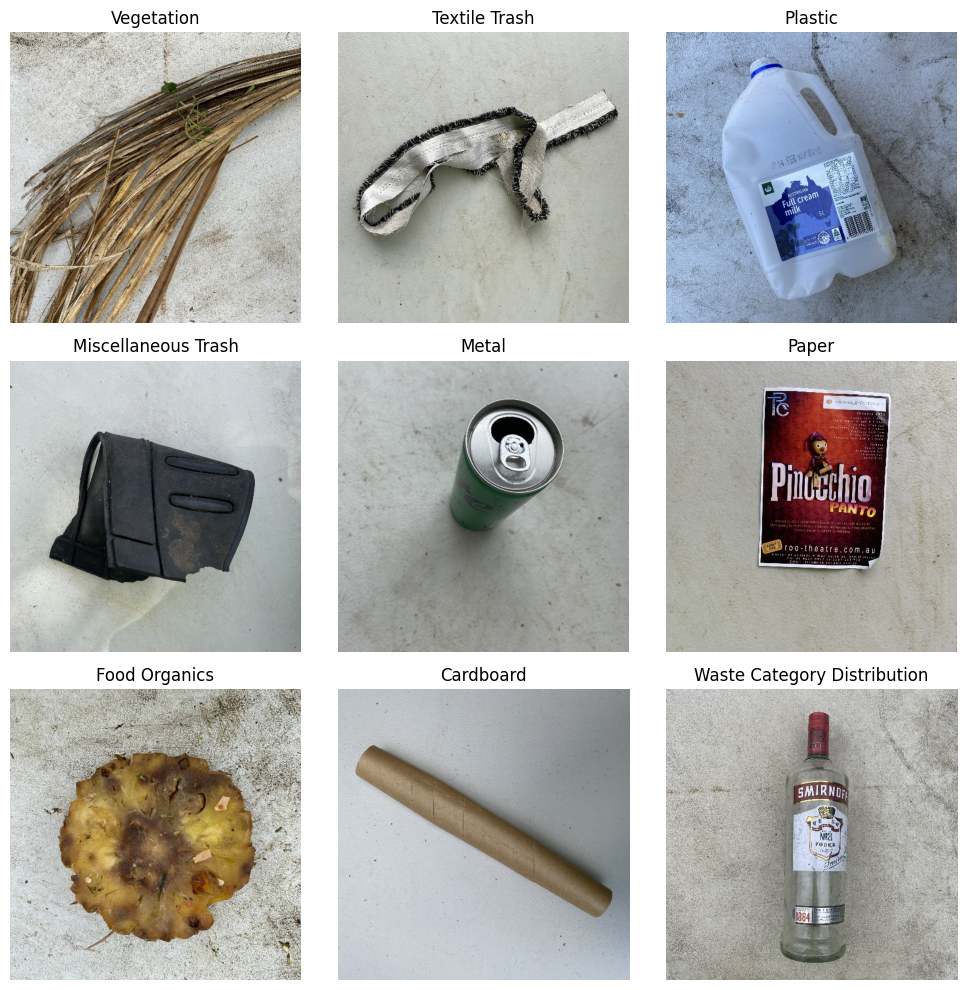

In [14]:
# Let visualize how the wasteset dataset look like,  showing first iage in each folder
# creating space for subplot contain 3 row, 3 column, total = 9 with 10 inch height and 10 inche wides
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
#itetrate over the 9 folders known as category
for ax, category in zip(axes.flat, os.listdir(dataset)):
    #pick each first image in each
    file = os.listdir(os.path.join(dataset, category))[0]
    #open it
    img = Image.open(os.path.join(dataset, category, file))
    # use the opening to plot the 9 subplots
    ax.imshow(img)
    #give it tittle
    ax.set_title(category)
    # no axis and grid line
    ax.axis("off")

# adjusts the layout and spacing.
plt.tight_layout()
plt.title("Waste Category Distribution")
plt.show()

In [15]:
# Import hashlib to generate digital fingerprints for checking duplicate images
import hashlib

In [16]:
# Store image filenames, categories, and their digital fingerprints
image_hashes = []

# Looping through to the dataset and it path
for category in os.listdir(dataset):
    category_path = os.path.join(dataset, category)
    #file locating in path
    for file in os.listdir(category_path):
        image_path = os.path.join(category_path, file)
        #Open the image in binary read mode and generate its digital fingerprint
        with open(image_path, "rb") as img:
            # converts them into a hexadecimal fingerprint
            image_hash = hashlib.md5(img.read()).hexdigest()
        # store each result into the empty Var list that was creates above
        image_hashes.append((file, category, image_hash))

# Organize the results in a DataFrame
hashes = pd.DataFrame(image_hashes, columns=["File", "Category", "Hash"])

# show dataframe with hash column
hashes

,File,Category,Hash
0,Vegetation_1.jpg,Vegetation,f37bd4538ba71e1ed5ea1239a39014da
1,Vegetation_10.jpg,Vegetation,317ed2b332f80638e7b213822985715c
2,Vegetation_100.jpg,Vegetation,6962caa3c3ffd1d8d3ba4fda56ed23c9
3,Vegetation_101.jpg,Vegetation,1ac47454ac01f975fe420ef9f213bb4b
4,Vegetation_102.jpg,Vegetation,e2567fc9794db6bd23a1507a36375919
...,...,...,...
4747,Glass_95.jpg,Glass,625a4fb15d4a0c70207c676ad9a63d53
4748,Glass_96.jpg,Glass,e9854fd95c1edcb40b0672a3c442fe1d
4749,Glass_97.jpg,Glass,1bcf552db42eb6b1cc44cf644603bfff
4750,Glass_98.jpg,Glass,f56c0d9fb2d0acaea60dc77ae124754e


In [17]:
# without not going through the whole table dataframe, let use print to find out the duplicate
# Count images and exact duplicates
print("Total images:", len(hashes))
print("Duplicate images:", hashes["Hash"].duplicated().sum())

Total images: 4752
Duplicate images: 0


## 3. Seperate Feature (X) and Target (y) and its Identification

**X (Features):** The image file paths that identify where each waste image is stored, including its file extension, e.g., .jpg.

**y (Target Labels):** The correct numeric category labels assigned to each image, e.g., 0 for Cardboard_1.jpg, 0 for Cardboard_40.jpg, and 1 for Food Organics images.

**Purpose:** X identifies the images the model will learn from, while y provides the correct waste categories the model should learn to predict.

In [18]:
# the main PyTorch library for building and training deep learning models.
import torch
# provides tools for working with images and computer vision.
import torchvision
#Lets us load Realwaste dataset, images using ImageFolder
from torchvision import datasets

In [19]:
#Lets load our dataset here first and assigned a new variable
# creating a new variable known as realwaste_data using touch to locate it root
realwaste_data = datasets.ImageFolder(root=dataset)

print("Total images:", len(realwaste_data)) # show the length of the total image
print("Waste categories:", realwaste_data.classes)# .classes is show the subfolder or hpw theyre categorize
print("Category labels:", realwaste_data.class_to_idx)

Total images: 4752
Waste categories: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Category labels: {'Cardboard': 0, 'Food Organics': 1, 'Glass': 2, 'Metal': 3, 'Miscellaneous Trash': 4, 'Paper': 5, 'Plastic': 6, 'Textile Trash': 7, 'Vegetation': 8}


In [20]:
# Extract image paths for (X)
X = [path for path, label in realwaste_data.samples]
# Extract their category labels (Paper,Plastics,Metal e.tc) for y
Y = [label for path, label in realwaste_data.samples]
# Check the extracted data through print
print("Total image paths (X):", len(X)) #print the total len of x feature which is 4,752 count on each image path
print("Example image path:", X[0])# the example of what x look like retrive first value(full path showing)
print("Total target labels (y):", len(Y)) # same sum as x but it only range from (0 to 8)
print("Example target label:", Y[0]) # same for y, retrieve the first value 0

Total image paths (X): 4752
Example image path: //content/drive/MyDrive/Smart Waste Recognition AI/RealWaste/Cardboard/Cardboard_1.jpg
Total target labels (y): 4752
Example target label: 0


In [21]:
# What do x and y look like in a real dataframe table
# Create a DataFrame showing image paths and their labels
xy_df = pd.DataFrame({"X (Image Path)": X,"Y (Numeric Label)": Y})

# Add the actual category name
xy_df["Waste Category"] = [realwaste_data.classes[label] for label in Y]

# Display the first 10 rows
xy_df

,X (Image Path),Y (Numeric Label),Waste Category
0,//content/drive/MyDrive/Smart Waste Recognitio...,0,Cardboard
1,//content/drive/MyDrive/Smart Waste Recognitio...,0,Cardboard
2,//content/drive/MyDrive/Smart Waste Recognitio...,0,Cardboard
3,//content/drive/MyDrive/Smart Waste Recognitio...,0,Cardboard
4,//content/drive/MyDrive/Smart Waste Recognitio...,0,Cardboard
...,...,...,...
4747,//content/drive/MyDrive/Smart Waste Recognitio...,8,Vegetation
4748,//content/drive/MyDrive/Smart Waste Recognitio...,8,Vegetation
4749,//content/drive/MyDrive/Smart Waste Recognitio...,8,Vegetation
4750,//content/drive/MyDrive/Smart Waste Recognitio...,8,Vegetation


## 4. Dataset Splitting for Train, Test and Validation


We'll divide the 4,752 waste images into training, validation, and test sets while keeping the nine categories represented proportionally.

Split the dataset

We'll use a 70% training, 15% validation, and 15% test split. We want our validation data unseen during validating so it better to split it now and  We'll also use stratify so each set keeps approximately the same proportion of images from each category, this come before preprocessing becase data leakage

In [22]:
# from sklearn, import ther function to use to split the data
from sklearn.model_selection import train_test_split

In [23]:
# Split off 15%, 0.15 for (y_train, y_test) for testing and
# the remain for Validation which about 85% for now (x_train_val, y_train_val)

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, #the X we created during seperation (image full file path and it values)
    Y, #the Y we created during seperation (image numeric label)
    test_size=0.15, #15% for all the test size in both x,y
    stratify= Y, # same proportion for each category during splitting
    random_state=42 #keep output the same for each run
    )

# We Split the remaining 85% data for actual x_train, and y train while about 15%,0.1765 go to valid training
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,  #for x_train_val, keep approx 15% out remain 85%
    y_train_val,  #for y_train_val, keep approx 15% out remain 8%%
    test_size=0.1765,  # Reserve about 15% of the original dataset for validation
    stratify=y_train_val,  # Preserve category proportions in the split
    random_state=42  #keep output the same for each run
)

print("70% data for Feature Training:", len(X_train))
print("15% data for Feature Testing:", len(X_test))
print("70% data for Target Training:", len(y_train))
print("15% data for Target Testing:", len(y_test))
print("15% data for Feature Validation:",len(X_val))
print("15% data for Target Validation:",len(y_val))

70% data for Feature Training: 3326
15% data for Feature Testing: 713
70% data for Target Training: 3326
15% data for Target Testing: 713
15% data for Feature Validation: 713
15% data for Target Validation: 713



## 5. Image Transformation, Preprocessing and Dataloader

RealWaste images are already RGB and approximately 524 x 524, but we'll transform and covert to tensor, by resizing them to 224 x 224 , a practical size for our initial CNN and later comparison with a pretrained Vision Transformer

Creating Transformation pipeline

In [24]:
# We used transforms tools in touchvision lib to prepare our image for resize, convert and normalize
from torchvision import transforms

In [25]:
# Building transformation pipeline
# combines these params into one transformation pipeline.
images_transform = transforms.Compose([
    transforms.Resize((224, 224)), # resize images it default from 524 to 224
    transforms.ToTensor(), # Converts images into a PyTorch tensor and scales pixel values (from 0–255 to 0–1)
    transforms.Normalize(mean=[0.485, 0.456, 0.406],std=[0.229, 0.224, 0.225]) # normalized for pre-trained ViT model,(so we dont have to transform and preprocess for pretrain VITs again)
])

In [26]:
# for verifying and cheking our transformation pipeline, (we use one image for an example)
# load one image first from the full path X
image = Image.open(X[0])

# Apply the pipeline variable (images_transform) to the one image we just retrieved to verify and check
confirm_img_transform = images_transform(image)

# Check the result on
print("The shape:", confirm_img_transform.shape) #checking the img tensor shape
print("The dataType:", confirm_img_transform.dtype)#checking the img tensor dtype
print("Minimum pixel value:", confirm_img_transform.min().item())#checking the img tensor smallest num(.item convert to python num)
print("Maximum pixel value:", confirm_img_transform.max().item())#checking the img tensor highest num (.item convert to python num)

The shape: torch.Size([3, 224, 224])
The dataType: torch.float32
Minimum pixel value: -1.5430065393447876
Maximum pixel value: 2.0299782752990723


Applying Transformations Using OOP
We use a custom `WasteDataset` class to apply our transformation pipeline to each image when it is loaded.
This prepares images as tensors of a consistent size and normalized values before they are passed to the model.

In [27]:
# a tool from PyTorch that helps us organise data so a model can access it one item at a time.
from torch.utils.data import Dataset

In [28]:
# Create our custom dataset class, inheriting from PyTorch's Dataset class
class WasteDataset(Dataset):

    # Initialise each dataset object with image paths, labels, and an optional transformation
    def __init__(self, X, y, transform=None):

        self.X = X  # Store the image paths inside this dataset object
        self.y = y  # Store the matching numeric labels inside this dataset object
        self.transform = transform  # Store the image transformation recipe

    # Tell PyTorch how many images this dataset contains
    def __len__(self):
        return len(self.X)  # Return the total number of image paths

    # Tell PyTorch how to retrieve one image and its matching label by index
    def __getitem__(self, index):

        image = Image.open(self.X[index])  # Open the image at the requested index
        label = self.y[index]  # Get the correct label for that same image

        if self.transform:  # Check whether a transformation recipe was provided
            image = self.transform(image)  # Apply the recipe to prepare the image as a tensor

        return image, label  # Return the prepared image and its matching label


# Create the training dataset using the training images, labels, and transformation recipe
train_dataset = WasteDataset(X_train, y_train, images_transform)

# Create the validation dataset using the validation images, labels, and transformation recipe
val_dataset = WasteDataset(X_val, y_val, images_transform)

# Create the testing dataset using the testing images, labels, and transformation recipe
test_dataset = WasteDataset(X_test, y_test, images_transform)

Batch Loading Using DataLoader

We will load our transformed dataset through batches, We divide images into smaller batches to reduce memory usage and process multiple images efficiently.
A batch size of 32 allows the model to learn from 32 images at a time and update its weights during training.

In [29]:
 #DataLoader to deliver dataset\all images to the model in manageable batches size rather than one image at a time.
from torch.utils.data import DataLoader

In [30]:
#batch_size=32: The model receives up to 32 images per batch.
#shuffle=True: Randomly changes the order of training samples each time you iterate through the loader. This helps prevent the model from learning from a fixed data order.
#shuffle=False: for validation and test datasets because we want consistent and predictable evaluation results.


# for train dataset, we use dataloader func, batch_size of 32 and shuffle, store in a var called train_loader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
# for validation dataset, we use dataloader func, batch_size of 32 and No shuffle, store in a var called val_loader
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
#for test dataset, we use dataloader func, batch_size of 32 and No shuffle, store in a var called test_loader
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [31]:
# Confirmation of our batch dataloader for (train_loader, val_loader, test_loadenr) through their next batchsize
#NB : images still represent feature x and label represent target y

# Check the training batch
images, labels = next(iter(train_loader)) #show for the next itetration
print("--------------------")
print("Training image batch shape:", images.shape)
print("Training label batch shape:", labels.shape)
print("Train Loader batches:", len(train_loader))

# Check the validation batch
images, labels = next(iter(val_loader))#check for the next itetration
print("--------------------")
print("Validation image batch shape:", images.shape)
print("Validation label batch shape:", labels.shape)
print("Validation Loader batches:", len(val_loader))

# Check the testing batch
images, labels = next(iter(test_loader))#check for the next itetration
print("--------------------")
print("Testing image batch shape:", images.shape)
print("Testing label batch shape:", labels.shape)
print("Test Loader batches:", len(test_loader))

--------------------
Training image batch shape: torch.Size([32, 3, 224, 224])
Training label batch shape: torch.Size([32])
Train Loader batches: 104
--------------------
Validation image batch shape: torch.Size([32, 3, 224, 224])
Validation label batch shape: torch.Size([32])
Validation Loader batches: 23
--------------------
Testing image batch shape: torch.Size([32, 3, 224, 224])
Testing label batch shape: torch.Size([32])
Test Loader batches: 23


## 6. Build a CNN from Scratch Model 1

We will define the Convolutional Neural Networks CNN architecture by specifying its layers, neurons, and activation functions.
The model will learn from our training images to classify waste into 9 categories.

In [32]:
# imports PyTorch Neural Network tools alias as nn, make use to use the cnn model (Conv2d)
import torch.nn as nn

In [33]:
# arrange neural network layers in order and the output from one layer becomes the input to the next,store all result in var called cnn_model1
# NB: filter or feature map means the same, the pattern such as (edge,textures, and shapes.) layers learns from

cnn_model1 = nn.Sequential(
    #first layer
    nn.Conv2d(3, 32, kernel_size=3, padding=1),#3 rgb as input, 32 num of filter or feature map the layer learns from, kernel_size=3 is Each filter examines a 3 × 3 area., padding = 1 is keep the padding same or preserve the image's height and width during output.
    nn.ReLU(), # activation func, change negative value to zero, positive num stay the same
    nn.MaxPool2d(2), #reduce the dimension by 2 or half so the width and height can shrink during training from (224 × 224 to 112 × 112)

    #second layer
    nn.Conv2d(32, 64, kernel_size=3, padding=1), #32 is Takes those 32 filter/features from previous layer 1 as input for this second, then learns 64 new feature maps or filter.
    nn.ReLU(), # activation func, change negative value to zero, positive num stay the same
    nn.MaxPool2d(2), #reduce the dimension by 2 or half so the width and height can shrink during training from (112 × 112 to 56 x 56)


    #final layer
    nn.Flatten(), #Reshape feature maps into one long vector per image,using flatten (vector is 200,704)
    nn.Linear(64 * 56 * 56, 128), # 64 x 56 x 56 = 200,704 which become input x 128(hidden layer choose by me) =25,690,112..using flatten , convert the vector to just 128 useful features map
    nn.ReLU(), #activation func
    nn.Linear(128, 9) #use that 128 useful feature to get 9 score for each category in our label (which also 9)
)

Calculation of **our** Parameter for Model 1

- layer 1 (the kernel filter size) 3 x 3 (the RGB) x 3 = 27 + 1 (1 bias per filter default)= 28 x 32 (num of feature map) = 896, in simple math
(3 x 3 x 3 + 1 ) x 32 = 896

- layer 2
(the kernel filter size) 3 x 3 (the second input) x 32 = 288 + 1 (1 bias per filter default)= 28 x 64 (num of feature map) = 18,469, in simple math
(3 x 3 x 32 + 1 ) x 64 = 18,469

- The first fully connected layer
64 x 56 x 56 = 200,704 x 128(selectively pick) = 25,690,112, then from 25,690,112 + 128(served as bias here again) = 25,690,240

- Final output layer
The 128 features connect to 9 output neurons, one for each waste category. (128 x 9 + 9) = 1,161

**Total Parameter in version 1**

896 + 18,496 + 25,690,240 + 1,161
= 25,710,793

Our first CNN had over 25,710,793 total parameter + weights in its fully connected layer. We will use AdaptiveAvgPool2d() to reduce the feature maps, making the model more memory-efficient.

nn.AdaptiveAvgPool2d() reduces the size of feature maps  

The goal is to make the CNN smaller and more memory-efficient while still predicting all nine waste categories

## 7. Build, Train, Validate, Test, Evaluate and Compare CNN from Scratch Model


**Build**

In [34]:
# here we are reducing the first cnn model by creating a new one with AdaptiveAvgPool2d()
# we will build it the way we built the first model, only AdaptiveAvgPool2d() is the new func

cnn_model2 = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1), #3 rgb as input, 32 num of filter or feature map the layer learns from, kernel_size=3 is Each filter examines a 3 × 3 area., padding = 1 is keep the padding same or preserve the image's height and width during output.
    nn.ReLU(),# activation func, change negative value to zero, positive num stay the same
    nn.MaxPool2d(2),  #reduce the dimension by 2 or half so the width and height can shrink during training from (224 × 224 to 112 × 112)


    nn.Conv2d(32, 64, kernel_size=3, padding=1),  #32 is Takes those 32 filter/features from previous layer 1 as input for this second, then learns 64 new feature maps or filter.
    nn.ReLU(), #activation func, change negative value to zero, positive num stay the same
    nn.MaxPool2d(2),#reduce the dimension by 2 or half so the width and height can shrink during training from (112 × 112 to 56 × 56)


    nn.AdaptiveAvgPool2d((1, 1)),  # Reduce each feature map by 1 x 1 ratio,(56 × 56 to 1 × 1)
    nn.Flatten(),                  # with flatten, we Convert the 64 feature maps into 64 useful values
    nn.Linear(64, 9)               # #use that 64 feature map to get 9 score for each category in our 9 label (Produce 9 class scores)
)

**Calculation of our Parameter for Model 2**

- layer 1 (the kernel filter size) 3 x 3 (the RGB) x 3 = 27 + 1 (1 bias per filter default)= 28 x 32 (num of feature map) = 896, in simple math
(3 x 3 x 3 + 1 ) x 32 = 896

- layer 2
(the kernel filter size) 3 x 3 (the second input) x 32 = 288 + 1 (1 bias per filter default)= 28 x 64 (num of feature map) = 18,469, in simple math
(3 x 3 x 32 + 1 ) x 64 = 18,469

- Adaptive Average Pooling Layer
nn.AdaptiveAvgPool2d((1, 1)) reduces each of the 64 feature maps from 56 × 56 to 1 × 1, leaving 64 values.
It has 0 learnable parameters because it performs averaging without learning weights or biases.
Flatten Layer
nn.Flatten() reshapes the output from 64 × 1 × 1 into 64 features per image.
It has 0 learnable parameters because it only reshapes the data.

- Final output layer(fully connected layer)
nn.Linear(64, 9)
64 input features × 9 output neurons = 576 weights + 9 biases (one per output neuron) = 585 parameters. in simple math,(64 × 9) + 9 = 585

**Total Parameter in version 2**

896 + 18,496 + 585 = 19,977

Version 2 has 19,977 total parameters across its convolutional and linear layers.compared with 25,710,793 parameters across the two linear layers in Version 1.

We define CrossEntropyLoss() to measure the model's classification errors and the Adam optimizer to update its learnable parameters. The CNN is trained in batches using a loop, where each batch produces predictions, calculates loss, computes gradients, and updates the model's weights. Validation is then used to monitor performance on unseen validation images dataset.

**Train**

In [35]:
# creating loss func recipe using CrossEntropyLoss() commonly used for multi-class classification.
#loss function tells how wrong prediction compare to right (mistakes measurement)
loss_func= nn.CrossEntropyLoss()

# creating optimizer func here using cnn_model2 and it parameters,learning rate to 0.001.
# optimizer adjust the model param, using the learning rate we assigned, this help us to reduce lossfunc
optimizer = torch.optim.Adam(cnn_model2.parameters(), lr=0.001)

The training Sequence is

Load images and labels --- Make predictions --- Calculate loss --- Calculate gradients (loss.backward()) --- Adjust parameters (optimizer.step()) --- Repeat for the next batch

NB: Training will goes through 10 epoch, the entire dataset (train_loader) will be trained in 10 cycle  

In [36]:
# Track the last completed epoch
start_epoch = 0

# Store training history
train_losses2 = []

# Set the total number of epochs
num_epochs = 10

# Check if a previous checkpoint exists
if os.path.exists(MODEL2_PATH):
    # Load the saved checkpoint
    checkpoint2 = torch.load(MODEL2_PATH, weights_only=False)

    # Restore model and optimizer states
    cnn_model2.load_state_dict(checkpoint2["model_state_dict"])
    optimizer.load_state_dict(checkpoint2["optimizer_state_dict"])

    # Restore the last completed epoch and training history
    start_epoch = checkpoint2["epoch"]
    train_losses2 = checkpoint2["train_losses"]

    print("Saved Model 2 checkpoint loaded!")
    print("Last completed epoch:", start_epoch)

else:
    print("No previous checkpoint found. Starting fresh training!")

# Resume training only if there are epochs remaining
if start_epoch < num_epochs:

    # Train the CNN model using training loops

    for epoch in range(start_epoch, num_epochs): #for every time you do the epochs through 10 times range (epoch loops)
        cnn_model2.train() #start the training here
        running_loss = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding as the batches progress or continue within the each epochs cycle(restart from 0 again after 1 epoch cycle completed-- 0.00, )

        for images, labels in train_loader: # every time you go through images,label in batch using(train_loader or x_train, y_train) (batch loop)
            optimizer.zero_grad() # clear the grad/gradient using backpropagation,before starting another one in new batc/epoch,

            outputs = cnn_model2(images) # all the images epoch pass through our model and produce prediction scores called logits(amount of accuracy scores for each class or labels)
            loss = loss_func(outputs, labels) # our loss function recipe work here, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss value or the mistakes measurement for every current batch e.g(batch 1 completed, batch 1 recorded 2.1 loss,  batch 1 take the loss and go and deposit it to runing loss, same goes for batch 2 during it turn and the rest).

            loss.backward() # Calculate gradients showing how model parameters contributed to the loss
            optimizer.step() # Adjust the model parameters using the calculated gradients( the optimizer do it works here)

            running_loss = running_loss + loss.item() # get variable (loss) result and convert into python num or change it from tensor to python int value .item(), then add it to the running_loss or (the total of loss accumulated at end of each current epoch is our running_loss e.g., losses of 1.2, 0.9, and 0.6 produce a total of 2.7 across three batches till the batches are fully completed and result stacks up)
        epoch_train_loss = running_loss / len(train_loader) # to get the loss result on each epoch cycle, scores of runing loss divide by the total len of the batch loader or the train_loader which is 104 batch (if a running loss on epoch is 150, then it would be 150/104 = 1.442, epoch loss is = 1.442), this happen like that on each epoch to the final one and the final is always the last epoch_loss scores , it also tend to reduce as epoch itetrate over and again till the last range)

        # Add the completed epoch loss to training history
        train_losses2.append(epoch_train_loss)

        print("Epoch:", epoch + 1, "/", num_epochs) #show which current epoch out of the total epoch e.g (1/10, 2/10)
        print("Training Loss:", round(epoch_train_loss, 4)) # show the average result (epoch_loss) of each loss in rounded digit or 4 decimal e.g (1.2346, 2.0405)
        print("--------------------") # print this to demarcate each result of the epochs

        # Save checkpoint after each completed epoch
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": cnn_model2.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_losses": train_losses2
        }, MODEL2_PATH)

        print("Model 2 checkpoint saved successfully!")
        print(os.path.exists(MODEL2_PATH))

    # Set the model to evaluation mode after training
    cnn_model2.eval()

else:
    # Set the model to evaluation mode when all epochs are complete
    cnn_model2.eval()
    print("Saved Model 2 loaded. Training already completed!")

Saved Model 2 checkpoint loaded!
Last completed epoch: 10
Saved Model 2 loaded. Training already completed!


In [37]:
# Load Model 2 checkpoint
checkpoint2 = torch.load(MODEL2_PATH, weights_only=False)

# Print Model 2 training losses
print("MODEL 2 TRAINING LOSSES")
for epoch, loss in enumerate(checkpoint2["train_losses"], start=1):
    print(f"Epoch {epoch}: {loss:.4f}")


MODEL 2 TRAINING LOSSES
Epoch 1: 2.0537
Epoch 2: 1.8986
Epoch 3: 1.8028
Epoch 4: 1.7214
Epoch 5: 1.6592
Epoch 6: 1.6074
Epoch 7: 1.5524
Epoch 8: 1.5251
Epoch 9: 1.4868
Epoch 10: 1.4526


Training Results

The training loss decreased from 2.0537 to 1.4535 over 10 epochs, indicating that the CNN progressively improved its ability to learn patterns from the training images. Final Training Loss is 1.4535

 **Validate**

Validation

We evaluates the CNN on unseen validation images using (val_loader). It measures how well the model generalizes to images it has not trained on, without updating the model's parameters or calculating the gradient weight.

NB: Validation will goes through 1 epoch which is the entire dataset (val_loader) will be vaidated in a single cycle  

In [38]:

cnn_model2.eval() #Put the CNN model on evaluation mode using our cnn model and .eval()

running_val_loss = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding up till the last batch

with torch.no_grad(): # Disable gradient calculations, We disabled gradient calculations during validation because we are evaluating the model, not training it.( so no weight adjustment needed)

    for images, labels in val_loader:  #Process each validation batch, every time you go through images,label in batch using(val_loader or x_val, y_val) (batch loop) (Loop through every validation batch)

        val_output = cnn_model2(images) #Generate prediction scores (logits) #all the images get validated through the model and produce prediction scores called logits(amount of accuracy scores for each class or labels)

        val_loss = loss_func(val_output, labels) #Calculate the loss for the current batch, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss value or the mistakes measurement for every current batch e.g(batch 1 completed, batch 1 recorded 2.1 loss, batch 1 take the loss and go and deposit it to runing_loss, same goes for batch 2 during it turn and the rest).

        running_val_loss += val_loss.item() #get variable (val_loss) result and convert into python num or change it from tensor to python int value .item(), then add it to the running_loss or let say(the total of loss accumulated at end of validation is our running_loss e.g., losses of 1.2, 0.9, and 0.6 produce a total of 2.7 across three batches till the batches are fully completed and result stacks up)

epoch_val_loss = running_val_loss / len(val_loader) #to get the loss result on validation epoch cycle, scores of total runing_loss divide by the total len of the batches, val_loader batches is 23 batch (if a running_loss scores on a single epoch is 60, then it would be 60/23 = 2.608, the epoch loss is = 1.442), this happen like that on each epoch to the final one and the final is always the last epoch_loss scores as overall , loss tend to reduce as epoch itetrate over and again till the last epoch but validation is only going through 1 epoch beacause we are validating)

print("Validation Loss:", round(epoch_val_loss, 4)) #Display the final validation loss in rounded digit or 4 decimal

Validation Loss: 1.4954


Validation Results

The validation loss is 1.4963, slightly higher than the training loss of 1.4535 The small difference of 0.0396 suggests a relatively close training and validation performance.  Final Validation Loss is 1.4963

Visualize Training and Validation loss

Plot the training and validation loss across epochs to compare the model's learning progress and generalization performance.

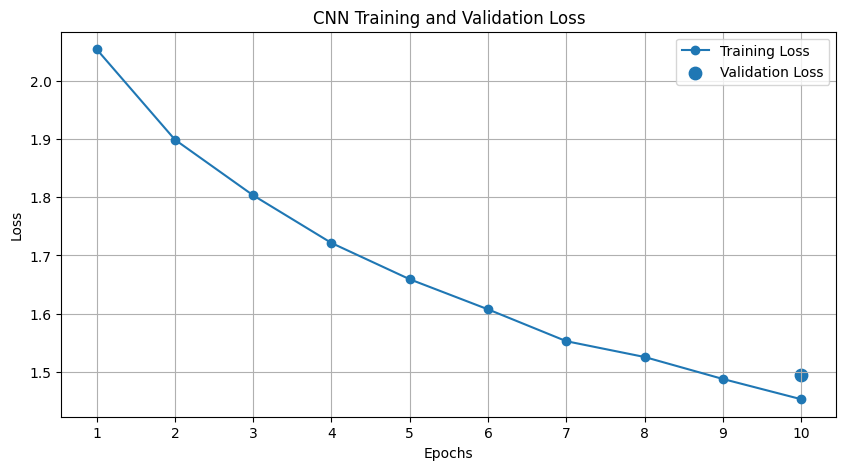

In [39]:
import matplotlib.pyplot as plt  # using matplot to create the line chart

all_epochs = range(1, 11)  # Generate epoch numbers from 1 to 10 and store them in all_epochs

train_losses = [2.0537, 1.8986, 1.8031, 1.7214, 1.6592, 1.6076, 1.5530, 1.5259, 1.4882, 1.4535] #store the training loss recorded across 10 epochs

val_loss = 1.4952  # Store the validation loss result here

plt.figure(figsize=(10, 5))  # Set the chart dimensions to 10 inches wide and 5 inches tall

plt.plot(all_epochs, train_losses, marker="o", label="Training Loss")  # Plot training loss across all 10 epochs

plt.scatter(10, val_loss, marker="o", s=80, label="Validation Loss")  # Mark the validation loss at epoch 10

plt.title("CNN Training and Validation Loss")  # chart title heading
plt.xlabel("Epochs")  # Label for the x-axis
plt.ylabel("Loss")  # Label for the y-axis

plt.xticks(all_epochs)  # Display each epoch number on the x-axis
plt.legend()  # Display labels identifying the training and validation results
plt.grid(True)  # Display grid lines to make loss values easier to read

plt.show()  #display the plot

 **Test**

The test dataset (test_loader) is evaluated in batches, with each test image processed once. There are no training epochs because the model's weights are not updated during testing.The test dataset contains unseen images used to evaluate the CNN's final performance and its ability to generalise to completely new data.

In [40]:
cnn_model2.eval() #Put the CNN model on evaluation mode using our cnn model and .eval()

running_test_loss = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding up till the last batch

with torch.no_grad(): # Disable gradient calculations, We disabled gradient calculations during validation because we are evaluating the model, not training it.( so no weight adjustment needed)

    for images, labels in test_loader:  #Process test_loader batch, every time you go through images,label in batch using(test_loader or x_test, y_test) (batch loop) (Loop through everytest_loader batch)

        test_output = cnn_model2(images) #Generate prediction scores (logits) #all the images get validated through the model and produce prediction scores called logits(amount of accuracy scores for each class or labels)

        test_loss = loss_func(test_output, labels) #Calculate the loss for the current batch, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss value or the mistakes measurement for every current batch e.g(batch 1 completed, batch 1 recorded 2.1 loss, batch 1 take the loss and go and deposit it to runing_loss, same goes for batch 2 during it turn and the rest).

        running_test_loss += test_loss.item()* images.size(0) # Convert the batch loss tensor to a Python number, multiply by the number of images(we use image this time to full accurate result from test_loader coz incase the last batch size isnt upto 32) in the current batch to get the total batch loss, and add it to the accumulated test loss
epoch_test_loss = running_test_loss / len(test_loader) #to get the loss result on testing epoch cycle, scores of total runing_loss divide by the total len of the batches, test_loader batches is 23 batch (if a running_loss scores on a single epoch is 60, then it would be 60/23 = 2.608, the epoch loss is = 1.442), this happen like that on each epoch to the final one and the final is always the last epoch_loss scores as overall , loss tend to reduce as epoch itetrate over and again till the last epoch but validation is only going through 1 epoch beacause we are validating)

print(f"Test Loss: {test_loss:.4f}")  ##Display the final Test loss in rounded digit or 4 decimal

Test Loss: 1.4756


The CNN achieved a test loss of 1.4784, indicating the average prediction error across the unseen test_loader images.

In [41]:
correct = 0  # Count correctly classified images (all correct image count stay inside here)
total = 0  # Count all tested images (all total image being tested stay inside here)

with torch.no_grad():  # Disable gradient calculations during testing
    for images, labels in test_loader:  #Loop through batches of test images
        outputs = cnn_model2(images)  #Generate predictions logits\logits  for the current batch (amount of higest accuracy scores for each class or labels e.g this image is on label 7, and logits bring out all the scores for the whole 9 label, whichever have the highest score is consider true here, even if it is wrong)

        predicted = torch.argmax(outputs, dim=1)  #Get the index of the highest prediction/logits score for each image (e.g. [0.2, 0.5, 1.8, 0.3] → class index 2 is the highest which is 1.8)

        total = total + len(images) # Get the actual number of images count in the current batch and add it to the variable total till the final images (e.g 32+ 32 + 32 + 16 = 112 images)

        correct = correct + (predicted == labels).sum().item() # Compare predicted classes with actual labels classes, and sum up the correct predictions after counting, convert the count to a Python number, and add it to the variable correct for each batches

test_accuracy = 100 * correct / total  # store this math in a var called test_accuracy by using correct var divide by total var and round it in percentage e,g(1600/3000 = 0.5333 which is 53.33%)

print(f"Correct Predictions: {correct}/{total}")  # show result both correct and total variable (stacking o n each other 358/713)
print(f"Test Accuracy: {test_accuracy:.2f}%")  # Display value of var test_accuracy

Correct Predictions: 358/713
Test Accuracy: 50.21%


The CNN correctly classified 358 out of 713 test images, achieving an accuracy of 50.21%.
This means the model correctly identified approximately half of the unseen waste images.

**Evaluate**


Collect the CNN's predicted class indices and their corresponding actual class indices and probabilites for ROC-AUC on all test images. These results will be used to create a Pandas DataFrame for comparison and calculate evaluation metrics, including accuracy, precision, recall, F1-score and confusion matrix and ROC-AUC

In [42]:
all_predictions = []  # Store the model's predicted class index for every test image
all_labels = []  # Store the actual class index for every test image
all_probabilities = []  # Store the predicted probabilities for all 9 classes (for ROC-AUC)

cnn_model2.eval()  # Set the CNN to evaluation mode

with torch.no_grad():  #Disable gradient calculations during testing
    for images, labels in test_loader:  #loop througb image and label for each batches in loader

        outputs = cnn_model2(images)  ##Generate predictions logits\logits  for the current batch (amount of higest accuracy scores for each class or labels e.g this image is on label 7, and logits bring out all the scores for the whole 9 label, whichever have the highest score is consider true here, even if it is wrong)

        predicted = torch.argmax(outputs, dim=1) #Get the index of the highest prediction/logits score for each image (e.g. [0.2, 0.5, 1.8, 0.3] → class index 2 is the highest which is 1.8)
        Probabilities = torch.softmax(outputs, dim=1)  #Convert logits into probabilities for the 9 classes (we use torch.softmax() to convert the model's raw outputs (logits) into probabilities)

        all_predictions.extend(predicted.cpu().tolist()) # change result from GPU to CPU incase, Convert batch predictions to a Python list(away from tensor) and add each predicted class index to all_predictions var list that was created above (e.g 6, 1, 3, 8,8 )
        all_labels.extend(labels.cpu().tolist())  # change result from GPU to CPU incase, Convert batch actual class/label to a Python list(away from tensor) and add each label/class index to all_labels var list that was created above (e.g class 0, 1, 5, 2, 3)
        all_probabilities.extend(Probabilities.cpu().tolist())  # Store probability scores for every image, convert probabilities to a Python list(away from tensor)


In [43]:
print("All Predictions:", all_predictions[:10])  #  show the first 10 predicted class to see
print("Actual Labels:", all_labels[:10])  #show the first 10 actual class to see if they match
print("All Probabilities:", all_probabilities[:10])  #  show the first 10 probabilities to see

print("Total Predictions:", len(all_predictions))  # Count all predictions collected
print("Total Labels:", len(all_labels))  # Count all actual labels collected, expect same count on both
print("Total Probabilities:",len(all_probabilities))  # Count all probabilities collected

All Predictions: [6, 1, 3, 8, 8, 6, 6, 6, 6, 6]
Actual Labels: [2, 1, 3, 8, 8, 5, 0, 3, 6, 0]
All Probabilities: [[0.009981914423406124, 0.0027563832700252533, 0.07293462753295898, 0.18471109867095947, 0.19523894786834717, 0.03607913479208946, 0.3443661332130432, 0.1281110793352127, 0.025820693001151085], [0.14183984696865082, 0.3761490285396576, 0.005966183263808489, 0.25231316685676575, 0.1200915277004242, 0.0365629568696022, 0.022075755521655083, 0.038616906851530075, 0.006384563632309437], [0.04212235286831856, 0.007196161895990372, 0.04665011912584305, 0.2881160378456116, 0.21973520517349243, 0.03802921995520592, 0.22519563138484955, 0.10485371947288513, 0.02810155786573887], [0.006598088424652815, 0.038616545498371124, 1.4605045180360321e-05, 0.13890540599822998, 0.042706336826086044, 0.011701851151883602, 0.0007239177939482033, 0.03399546071887016, 0.7267376780509949], [0.001938575180247426, 0.23930847644805908, 4.200131797915674e-09, 0.00010701729479478672, 0.000177882029674947

In [44]:
# to get better view on table of our all predictions and all labels and all probabilities we just retrieved in above cell, lets create table consisting each column using pd.frame
results_df = pd.DataFrame({"Actual Labels": all_labels,"Predicted Labels": all_predictions,"Probabilities": all_probabilities})

# show result
results_df

,Actual Labels,Predicted Labels,Probabilities
0,2,6,"[0.009981914423406124, 0.0027563832700252533, ..."
1,1,1,"[0.14183984696865082, 0.3761490285396576, 0.00..."
2,3,3,"[0.04212235286831856, 0.007196161895990372, 0...."
3,8,8,"[0.006598088424652815, 0.038616545498371124, 1..."
4,8,8,"[0.001938575180247426, 0.23930847644805908, 4...."
...,...,...,...
708,1,6,"[0.10286151617765427, 0.21278560161590576, 0.1..."
709,1,1,"[0.08621976524591446, 0.4747689962387085, 0.01..."
710,4,6,"[0.011186155490577221, 0.0051573216915130615, ..."
711,7,3,"[0.009026492945849895, 0.01463552750647068, 0...."


Classification performance using accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC. These metrics provide a detailed assessment of its predictive performance and its ability to distinguish between the nine waste categories.

In [45]:
# Import evaluation metrics, the 4 metrics are (accuracy_score, classification_report, confusion_matrix, roc_auc_score)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

In [46]:
# Print the Evaluate predictions for Accuracy Metrics
print("Accuracy:", accuracy_score(all_labels, all_predictions))

#Print the Evaluate predictions for Classifications Report
print("\nClassification Report:")
print(classification_report(all_labels, all_predictions))

#Print the Evaluate predictions for Confusion Matrix metrics
print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

#Print the Evaluate predictions for ROC_AUC
roc_auc = roc_auc_score(all_labels,all_probabilities,multi_class="ovr",average="macro") # Compare each class against the remaining 8 classes (=ovr means One-vs-Rest) and Calculate the average ROC-AUC across all 9 classes
print("\nMulticlass ROC-AUC (OvR):", round(roc_auc, 4))

Accuracy: 0.5021037868162693

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.48      0.49        69
           1       0.80      0.52      0.63        62
           2       0.61      0.54      0.57        63
           3       0.47      0.52      0.50       119
           4       0.29      0.09      0.14        74
           5       0.64      0.21      0.32        75
           6       0.41      0.78      0.53       138
           7       0.45      0.19      0.26        48
           8       0.66      0.89      0.76        65

    accuracy                           0.50       713
   macro avg       0.54      0.47      0.47       713
weighted avg       0.52      0.50      0.47       713


Confusion Matrix:
[[ 33   6   5   5   0   5  14   1   0]
 [  3  32   0   3   1   0   9   0  14]
 [  5   0  34   5   2   0  16   0   1]
 [  5   0   2  62   2   1  47   0   0]
 [  3   0   4  15   7   1  28   5  11]
 [  6   0   5  14   2  16  2

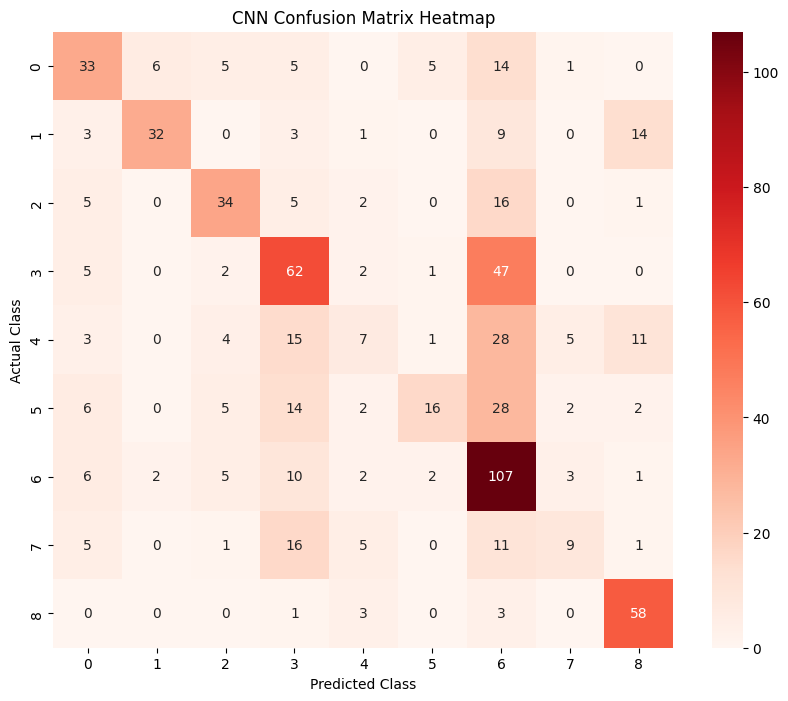

In [47]:
# Confusion Matrix heatmap
cm = confusion_matrix(all_labels, all_predictions)

# Plot the confusion matrix as a heatmap with figsize 10 inches width wide and 8 inches tall height
plt.figure(figsize=(10, 8))

# Display prediction counts as integers in a blue heatmap, with actual and predicted class labels from 0 to 8
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", xticklabels=range(9), yticklabels=range(9))
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN Confusion Matrix Heatmap")
plt.show()


**Output Explanation**

**Accuracy: 50.21%** — How often the CNN correctly predicts the waste category. The model correctly classified 358 out of 713 test images.

**Classification Report:**

- **Precision (Class 0): 50%** — Of all images predicted as Class 0, 50% actually belonged to Class 0.
- **Precision (Class 1): 80%** — Of all images predicted as Class 1, 80% actually belonged to Class 1.
- **Precision (Class 2): 61%** — Of all images predicted as Class 2, 61% actually belonged to Class 2.
- **Precision (Class 3): 47%** — Of all images predicted as Class 3, 47% actually belonged to Class 3.
- **Precision (Class 4): 29%** — Of all images predicted as Class 4, 29% actually belonged to Class 4.
- **Precision (Class 5): 64%** — Of all images predicted as Class 5, 64% actually belonged to Class 5.
- **Precision (Class 6): 41%** — Of all images predicted as Class 6, 41% actually belonged to Class 6.
- **Precision (Class 7): 45%** — Of all images predicted as Class 7, 45% actually belonged to Class 7.
- **Precision (Class 8): 66%** — Of all images predicted as Class 8, 66% actually belonged to Class 8.

**Recall:**
- Class 0: 48% — How many actual Class 0 images the model correctly identified.
- Class 1: 52% — How many actual Class 1 images the model correctly identified.
- Class 2: 54% — How many actual Class 2 images the model correctly identified.
- Class 3: 52% — How many actual Class 3 images the model correctly identified.
- Class 4: 9% —  How many actual Class 4 images the model correctly identified.
- Class 5: 21% — How many actual Class 5 images the model correctly identified.
- Class 6: 78% — How many actual Class 6 images the model correctly identified.
- Class 7: 19% — How many actual Class 7 images the model correctly identified.
- Class 8: 89% — How many actual Class 8 images the model correctly identified.

**F1-score:**
- Class 0: 0.49 — Combined measure of precision and recall.
- Class 1: 0.63 — Combined measure of precision and recall.
- Class 2: 0.57 — Combined measure of precision and recall.
- Class 3: 0.50 — Combined measure of precision and recall.
- Class 4: 0.14 — Combined measure of precision and recall.
- Class 5: 0.32 — Combined measure of precision and recall.
- Class 6: 0.53 — Combined measure of precision and recall.
- Class 7: 0.26 — Combined measure of precision and recall.
- Class 8: 0.76 — Combined measure of precision and recall.

- **Macro Average F1-score: 0.47** — Average F1-score across all nine classes, giving each class equal importance.
- **Weighted Average F1-score: 0.47** — Average F1-score across all nine classes, accounting for the number of actual images in each class.

**Confusion Matrix:**

- Row 0: `[33, 6, 5, 5, 0, 5, 14, 1, 0]` — 33 out of 69 Class 0 images were correctly predicted;
- Row 1: `[3, 32, 0, 3, 1, 0, 9, 0, 14]` — 32 out of 62 Class 1 images were correctly predicted;
- Row 2: `[5, 0, 34, 5, 2, 0, 16, 0, 1]` — 34 out of 63 Class 2 images were correctly predicted;
- Row 3: `[5, 0, 2, 62, 2, 1, 47, 0, 0]` — 62 out of 119 Class 3 images were correctly predicted;
- Row 4: `[3, 0, 4, 15, 7, 1, 28, 5, 11]` — 7 out of 74 Class 4 images were correctly predicted;
- Row 5: `[6, 0, 5, 14, 2, 16, 28, 2, 2]` — 16 out of 75 Class 5 images were correctly predicted;
- Row 6: `[6, 2, 5, 10, 2, 2, 107, 3, 1]` — 107 out of 138 Class 6 images were correctly predicted;
- Row 7: `[5, 0, 1, 16, 5, 0, 11, 9, 1]` — 9 out of 48 Class 7 images were correctly predicted;
- Row 8: `[0, 0, 0, 1, 3, 0, 3, 0, 58]` — 58 out of 65 Class 8 images were correctly predicted;

**Total:** 358 out of 713 test images were correctly classified, giving an accuracy of 50.21%.



**ROC-AUC (Receiver Operating Characteristic – Area Under the Curve)**

**Multiclass ROC-AUC (OvR): 0.851** Measures how well the CNN distinguishes each waste category from the other eight categories using prediction probabilities. A score of 0.851 indicates good class discrimination.

CNN Model 2 showed signs of underfitting or limited learning capacity, as its training and validation losses remained relatively high and its test accuracy was 50.21%.

We built CNN Model 3 to improve CNN Model 2's classification performance, particularly its weaker performance across some waste categories.

We introduced a third convolutional layer, Batch Normalization and Dropout to improve feature extraction, training stability and generalisation.

## 8. Build, Train, Validate, Test, Evaluate and Compare CNN from Scratch Model 3


We will improve CNN Model 2 by introducing a third convolutional layer in CNN Model 3, Batch Normalization and Dropout. We will retain Adaptive Average Pooling and the nine-class output layer. The new model will initially train for 15 epochs, with validation loss monitored throughout training.

In [48]:

# CNN model 3

cnn_model3 = nn.Sequential( #arrange multiple neural network layers in order, so the output of one layer automatically becomes the input of the next layer.

    nn.Conv2d(3, 32, kernel_size=3, padding=1), #3 rgb as input, 32 num of filter or feature map the layer learns from, kernel_size=3 is Each filter examines a 3 × 3 area., padding = 1 is keep the padding same or preserve the image's height and width during output.
    nn.BatchNorm2d(32), # normalizing and scaling it so numerical values can be distributed in a stable way using batch staistics like mean, variances (the 2d work for both height and width )
    nn.ReLU(), # activation func, change negative value to zero, positive num stay the same
    nn.MaxPool2d(2), #reduce the dimension by 2 or half so the width and height can shrink during training from (224 × 224 to 112 × 112)


    nn.Conv2d(32, 64, kernel_size=3, padding=1),  #32 is Takes those 32 filter/features from previous layer 1 as input for this second, then learns 64 new feature maps or filter.
    nn.BatchNorm2d(64), # normalizing and scaling it so numerical values can be distributed in a stable way using batch staistics mean, variances (the 2d work for both height and width )
    nn.ReLU(), # activation func, change negative value to zero, positive num stay the same
    nn.MaxPool2d(2), #reduce the dimension by 2 or half so the width and height can shrink during training from (112 × 112 to 56 × 56)


    nn.Conv2d(64, 128, kernel_size=3, padding=1),  # 64, is Takes those 64 filter/features from previous layer 2 as input for this second, then learns 128 new feature maps or filter.
    nn.BatchNorm2d(128),#normalizing and scaling it so numerical values can be distributed in a stable way using batch staistics like mean, variances (the 2d work for both height and width )
    nn.ReLU(),# activation func, change negative value to zero, positive num stay the same
    nn.MaxPool2d(2), #reduce the dimension by 2 or half so the width and height can shrink during training from (56 × 56 to 28 x 28)
    # Fully connected convolutional layer
    nn.AdaptiveAvgPool2d((1, 1)),   # Reduce each feature map by 1 x 1 ratio,(28 × 28 to 1 × 1)
    nn.Flatten(),  # Reshapes the 128 feature maps into one long vector per image (128 × 1 × 1 = 128 values, because AdaptiveAvgPool2d reduced each feature map from 28 × 28 to 1 × 1).
    nn.Dropout(0.3), #Randomly disables 30% of features map or neurons during training so the model dont rely too much on particular features, this helps prevent overfitting
    nn.Linear(128, 9)
)

print(cnn_model3)


Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): AdaptiveAvgPool2d(output_size=(1, 1))
  (13): Flatten(start_dim=1, end_dim=-1)
  (14): Dropout(p=0.3, inplace=False)
  (15): Linear(in_features=128, out_features=9, bias=True)


In [49]:
epochs = 15 # Number of times the cn model3 will learn from t dataset (15 times for both train_loader and Val_loader)

loss_func3 = nn.CrossEntropyLoss() #seting our crossentropyloss function (Calculate the classification error across our 9 waste categories)

optimizer3 = torch.optim.Adam(cnn_model3.parameters(),lr=0.001) #setting the optimizer for cnn model 3 to help us update and adjust the paramater using Adam and the learning rate 0.001

# Track the last completed epoch
start_epoch = 0

# Check if a previous checkpoint exists
if os.path.exists(MODEL3_PATH):

    # Load the saved checkpoint
    checkpoint3 = torch.load(MODEL3_PATH, weights_only=False)

    # Restore model and optimizer states
    cnn_model3.load_state_dict(checkpoint3["model_state_dict"])
    optimizer3.load_state_dict(checkpoint3["optimizer_state_dict"])

    # Restore the last completed epoch and training histories
    start_epoch = checkpoint3["epoch"]
    train_losses3 = checkpoint3["train_losses"]
    val_losses3 = checkpoint3["val_losses"]

    print("Saved Model 3 checkpoint loaded!")
    print("Last completed epoch:", start_epoch)

else:

    print("No previous checkpoint found. Starting fresh training!")

    train_losses3 = [] # Store training loss after each epoch (later be useful for visual)
    val_losses3 = [] # Store validation loss after each epoch (later be useful for visual)

# Resume training only if there are epochs remaining
if start_epoch < epochs:

    # (Epoch Loop target both train and val)
    for epoch in range(start_epoch, epochs):  #for every time you go through the epochs, do it within 5 times range (loops 5 times)

        cnn_model3.train() #bring out the cnn model here for training mode
        running_train3_loss = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding as the batches progress or continue within the each epochs cycle(restart from 0 again after 1 epoch cycle completed-- 0.00, )
        for images, labels in train_loader: #for every batch loss or any batch loss that keep coming, store it here and keep adding as the batches progress or continue within the each epochs cycle(restart from 0 again after 1 epoch cycle completed-- 0.00, )
            optimizer3.zero_grad()  #clear the grad/gradient using backpropagation,before starting another one in new batc/epoch,
            outputs = cnn_model3(images) # all the images epoch pass through our model and produce prediction scores called logits(amount of accuracy scores for each class or labels)
            loss = loss_func3(outputs, labels) # our loss function recipe work here, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss valu
            loss.backward() #Calculate gradients showing how model parameters contributed to the loss
            optimizer3.step() #Adjust the model parameters using the calculated gradients( the optimizer do it works here)
            running_train3_loss = running_train3_loss + loss.item() * images.size(0) #(we use image.size(0) this time to get full accurate result from train_loader coz incase the last batch size isnt upto 32), (get result and convert into python num or change it from tensor to python int value .item(), then add it to the running_vtrain_loss or let say(the total of loss accumulated at end of training is our running_vtrain_loss e.g., losses of 1.2, 0.9, and 0.6 produce a total of 2.7 across three batches till the batches are fully completed and result stacks up)

        epoch_train3_loss = running_train3_loss / len(train_loader.dataset) # to get the loss result on each epoch cycle, scores of runing loss divide by the total len of the batch loader or the train_loader which is 104 batch (if a running loss on epoch is 150, then it would be 150/104 = 1.442, epoch loss is = 1.442), this happen like that on each epoch to the final one and the final is always the last epoch_loss scores , it also tend to reduce as epoch itetrate over and again till the last range)
        train_losses3.append(epoch_train3_loss) # with that result you get on epoc_train3_loss, add it as a list on var vit_training_losses


        cnn_model3.eval() #setting the cnn model 3 for validation mode
        running_val3_loss = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding as the batches progress or continue within the each epochs cycle(restart from 0 again after 1 epoch cycle completed-- 0.00, )

        with torch.no_grad(): # Disable gradient calculations, We disabled gradient calculations during validation because we are evaluating the model, not training it and it serves as unseen dataset.( so no weight adjustment needed)
            for images, labels in val_loader: # Process each validation batch, every time you go through images,label in batch using(val_loader or x_val, y_val) (batch loop) (Loop through every validation batch)
                outputs = cnn_model3(images) # Generate prediction scores (logits) #all the images get validated through the model and produce prediction scores called logits(amount of accuracy scores for each class or labels)
                loss = loss_func3(outputs, labels)  #Calculate the loss for the current batch, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss value or the mistakes measurement for every current batch e.g(batch 1 completed, batch 1 recorded 2.1 loss, batch 1 take the loss and go and deposit it to runing_loss, same goes for batch 2 during it turn and the rest).
                running_val3_loss = running_val3_loss + loss.item() * images.size(0) #(we use image.size(0) this time to get full accurate result from val_loader coz incase the last batch size isnt upto 32), (get result and convert into python num or change it from tensor to python int value .item(), then add it to the running_vval_loss or let say(the total of loss accumulated at end of training is our running_vval_loss e.g., losses of 1.2, 0.9, and 0.6 produce a total of 2.7 across three batches till the batches are fully completed and result stacks up)
        epoch_val3_loss = running_val3_loss / len(val_loader.dataset) #to get the loss result on validation epoch cycle, scores of total runing_loss divide by the total len of the batches, val_loader batches is 23 batch (if a running_loss scores on a single epoch is 60, then it would be 60/23 = 2.608, the epoch loss is = 1.442), this happen like that on each epoch to the final one and the final is always the last epoch_loss scores as overall , loss tend to reduce as epoch itetrate over and again till the last epoch
        val_losses3.append(epoch_val3_loss) # with that result you get on epoch_vval_loss, add it as a list on var vit_val_losses


        print(f"Epoch: {epoch + 1} / {epochs}") #show which current epoch out of the total epoch e.g (1/10, 2/10)
        print(f"Training Loss: {epoch_train3_loss:.4f}") # show the average result of each epoch loss in rounded digit or 4 decimal e.g (1.2346, 2.0405)
        print(f"Validation Loss: {epoch_val3_loss:.4f}")  #Display the final validation loss in rounded digit or 4 decimal
        print("--------------------") # Print a separator between epochs

        # Save checkpoint after each completed epoch
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": cnn_model3.state_dict(),
            "optimizer_state_dict": optimizer3.state_dict(),
            "train_losses": train_losses3,
            "val_losses": val_losses3
        }, MODEL3_PATH)

        print("Model 3 checkpoint saved successfully!")
        print(os.path.exists(MODEL3_PATH))

    # Set the model to evaluation mode after training
    cnn_model3.eval()

else:
    # Set the model to evaluation mode when all epochs are complete
    cnn_model3.eval()
    print("Saved Model 3 loaded. Training already completed!")

Saved Model 3 checkpoint loaded!
Last completed epoch: 15
Saved Model 3 loaded. Training already completed!


In [50]:
# Load Model 3 checkpoint
checkpoint3 = torch.load(MODEL3_PATH, weights_only=False)

# Print Model 3 training and validation losses
print("\nMODEL 3 TRAINING AND VALIDATION LOSSES")

for epoch, (train_loss, val_loss) in enumerate(
    zip(checkpoint3["train_losses"], checkpoint3["val_losses"]), start=1
):
    print(f"Epoch {epoch}: Training Loss: {train_loss:.4f} | Validation Loss: {val_loss:.4f}")


MODEL 3 TRAINING AND VALIDATION LOSSES
Epoch 1: Training Loss: 1.6928 | Validation Loss: 1.5331
Epoch 2: Training Loss: 1.4333 | Validation Loss: 1.4263
Epoch 3: Training Loss: 1.3546 | Validation Loss: 1.3659
Epoch 4: Training Loss: 1.2925 | Validation Loss: 1.3794
Epoch 5: Training Loss: 1.2597 | Validation Loss: 1.2987
Epoch 6: Training Loss: 1.2126 | Validation Loss: 1.3379
Epoch 7: Training Loss: 1.1923 | Validation Loss: 1.2887
Epoch 8: Training Loss: 1.1968 | Validation Loss: 1.2031
Epoch 9: Training Loss: 1.1661 | Validation Loss: 1.2570
Epoch 10: Training Loss: 1.1361 | Validation Loss: 1.0788
Epoch 11: Training Loss: 1.1048 | Validation Loss: 1.2185
Epoch 12: Training Loss: 1.1089 | Validation Loss: 1.1462
Epoch 13: Training Loss: 1.0846 | Validation Loss: 1.0638
Epoch 14: Training Loss: 1.0724 | Validation Loss: 1.1603
Epoch 15: Training Loss: 1.0494 | Validation Loss: 1.3838


Lets visualize how the cnn model 3 behave across the 5 epoch between train_loader and val_loader using line chart

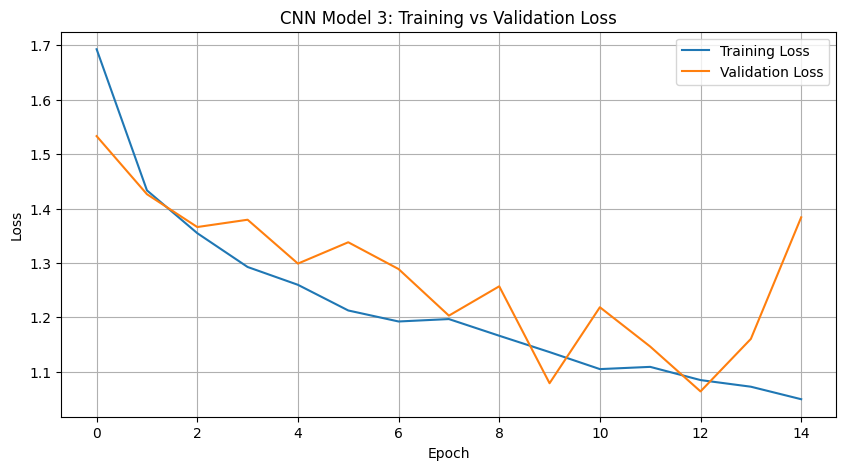

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5)) # Set the chart dimensions to 10 inches wide and 5 inches tall

plt.plot(train_losses3, label="Training Loss") # Plot training loss across all 5 epoch
plt.plot(val_losses3, label="Validation Loss") # Plot training loss across all 5 epoch

plt.title("CNN Model 3: Training vs Validation Loss") # title heading
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend() #Display labels identifying the training and validation results
plt.grid()
plt.show()

Now we evaluate CNN model 3 on test datasert using test_loader ansd from there we performed the usual evaluation metrics such as classification reports, confusion matrix and roc_auc

In [52]:
cnn_model3.eval() #Put the CNN model on evaluation mode using our cnn model and .eval()

running_test3_loss = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding up till the last batch

with torch.no_grad(): # Disable gradient calculations, We disabled gradient calculations during validation because we are evaluating the model, not training it.( so no weight adjustment needed)

    for images, labels in test_loader:  #Process test_loader batch, every time you go through images,label in batch using(test_loader or x_test, y_test) (batch loop) (Loop through everytest_loader batch)

        test3_output = cnn_model3(images) #Generate prediction scores (logits) #all the images get validated through the model and produce prediction scores called logits(amount of accuracy scores for each class or labels)

        test3_loss = loss_func(test3_output, labels) #Calculate the loss for the current batch, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss value or the mistakes measurement for every current batch e.g(batch 1 completed, batch 1 recorded 2.1 loss, batch 1 take the loss and go and deposit it to runing_loss, same goes for batch 2 during it turn and the rest).

        running_test3_loss += test3_loss.item()* images.size(0) # Convert the batch loss tensor to a Python number, multiply by the number of images(we use image this time to full accurate result from test_loader coz incase the last batch size isnt upto 32) in the current batch to get the total batch loss, and add it to the accumulated test loss

epoch_test3_loss = running_test3_loss / len(test_loader.dataset) # Divide the accumulated test loss by the total number of test images to calculate the average test loss

print(f"Test Loss: {epoch_test3_loss:.4f}") #Display the final Test loss in rounded digit or 4 decimal

Test Loss: 1.4284


In [53]:
correct3 = 0  # Count correctly classified images (all correct image count stay inside here)
total3 = 0  # Count all tested images (all total image being tested stay inside here)

with torch.no_grad():  # Disable gradient calculations during testing
    for images, labels in test_loader:  #Loop through batches of test images
        outputs = cnn_model3(images)  #Generate predictions logits\logits  for the current batch (amount of higest accuracy scores for each class or labels e.g this image is on label 7, and logits bring out all the scores for the whole 9 label, whichever have the highest score is consider true here, even if it is wrong)

        predicted3 = torch.argmax(outputs, dim=1)  #Get the index of the highest prediction/logits score for each image (e.g. [0.2, 0.5, 1.8, 0.3] → class index 2 is the highest which is 1.8)

        total3 = total3 + len(images) # Get the actual number of images count in the current batch and add it to the variable total till the final images (e.g 32+ 32 + 32 + 16 = 112 images)

        correct3 = correct3 + (predicted3 == labels).sum().item() # Compare predicted classes with actual labels classes, and sum up the correct predictions after counting, convert the count to a Python number, and add it to the variable correct for each batches

test3_accuracy = 100 * correct3 / total3  # store this math in a var called test_accuracy by using correct var divide by total var and round it in percentage e,g(1600/3000 = 0.5333 which is 53.33%)

print(f"Correct Predictions: {correct3}/{total3}")  # show result both correct and total variable (stacking o n each other 358/713)
print(f"Test Accuracy: {test3_accuracy:.2f}%")  # Display value of var test_accuracy

Correct Predictions: 370/713
Test Accuracy: 51.89%


The CNN model 3 correctly classified 370 out of 713 test images, achieving an accuracy of 51.89%. This means the model correctly identified approximately half of the unseen waste images

In [54]:
all_predictions3 = []  # Store the model's predicted class index for every test image
all_labels3 = []  # Store the actual class index for every test image
all_probabilities3 = []  # Store the predicted probabilities for all 9 classes (for ROC-AUC)

cnn_model3.eval()  # Set the CNN to evaluation mode

with torch.no_grad():  #Disable gradient calculations during testing
    for images, labels in test_loader:  #loop througb image and label for each batches in loader

        outputs3 = cnn_model3(images)  ##Generate predictions logits\logits  for the current batch (amount of higest accuracy scores for each class or labels e.g this image is on label 7, and logits bring out all the scores for the whole 9 label, whichever have the highest score is consider true here, even if it is wrong)

        predicted3 = torch.argmax(outputs3, dim=1) #Get the index of the highest prediction/logits score for each image (e.g. [0.2, 0.5, 1.8, 0.3] → class index 2 is the highest which is 1.8)
        Probabilities3 = torch.softmax(outputs3, dim=1)  #Convert logits into probabilities for the 9 classes (we use torch.softmax() to convert the model's raw outputs (logits) into probabilities)

        all_predictions3.extend(predicted3.cpu().tolist()) # change result from GPU to CPU incase, Convert batch predictions to a Python list(away from tensor) and add each predicted class index to all_predictions var list that was created above (e.g 6, 1, 3, 8,8 )
        all_labels3.extend(labels.cpu().tolist())  # change result from GPU to CPU incase, Convert batch actual class/label to a Python list(away from tensor) and add each label/class index to all_labels var list that was created above (e.g class 0, 1, 5, 2, 3)
        all_probabilities3.extend(Probabilities3.cpu().tolist())  # Store probability scores for every image, convert probabilities to a Python list(away from tensor)


In [55]:
print("All Predictions:", all_predictions3[:10])  #  show the first 10 predicted class to see
print("Actual Labels:", all_labels3[:10])  #show the first 10 actual class to see if they match
print("All Probabilities:", all_probabilities3[:10])  #  show the first 10 probabilities to see

print("Total Predictions:", len(all_predictions3))  # Count all predictions collected
print("Total Labels:", len(all_labels3))  # Count all actual labels collected, expect same count on both
print("Total Probabilities:",len(all_probabilities3))  # Count all probabilities collect

All Predictions: [3, 3, 3, 8, 8, 6, 6, 3, 6, 2]
Actual Labels: [2, 1, 3, 8, 8, 5, 0, 3, 6, 0]
All Probabilities: [[0.02292569912970066, 7.184029527707025e-05, 0.1379532665014267, 0.5139461159706116, 0.0785476416349411, 0.15961657464504242, 0.016332097351551056, 0.07055758684873581, 4.925142275169492e-05], [0.05934882164001465, 0.29184719920158386, 0.1661650687456131, 0.3111081123352051, 0.05184301733970642, 0.04565691202878952, 0.007180176675319672, 0.0421161949634552, 0.024734478443861008], [0.12773853540420532, 1.3317867342266254e-07, 0.027658920735120773, 0.7533425092697144, 0.010884774848818779, 0.060224320739507675, 0.0135116595774889, 0.0066389418207108974, 2.3508520996529114e-07], [0.005970713682472706, 0.07029928267002106, 0.008248467929661274, 0.08683361113071442, 0.10315003246068954, 0.03356395661830902, 0.0007694432279095054, 0.078520268201828, 0.6126442551612854], [0.019462037831544876, 0.015479984693229198, 8.673920092405751e-06, 0.040432464331388474, 0.0028839940205216408

In [56]:
# to get better view on table of our all predictions and all labels and all probabilities we just retrieved in above cell, lets create table consisting each column using pd.frame
results3_df = pd.DataFrame({"Actual Labels": all_labels3,"Predicted Labels": all_predictions3,"Probabilities": all_probabilities3})

# show result
results3_df

,Actual Labels,Predicted Labels,Probabilities
0,2,3,"[0.02292569912970066, 7.184029527707025e-05, 0..."
1,1,3,"[0.05934882164001465, 0.29184719920158386, 0.1..."
2,3,3,"[0.12773853540420532, 1.3317867342266254e-07, ..."
3,8,8,"[0.005970713682472706, 0.07029928267002106, 0...."
4,8,8,"[0.019462037831544876, 0.015479984693229198, 8..."
...,...,...,...
708,1,2,"[0.01918131299316883, 0.03295193985104561, 0.6..."
709,1,3,"[0.031865399330854416, 0.052676133811473846, 0..."
710,4,3,"[0.0043114866130054, 1.9023522327188402e-05, 0..."
711,7,3,"[0.017682164907455444, 0.038687814027071, 0.09..."


Classification performance using accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC on CNN model 3 test_loader results3

In [57]:
# Import evaluation metrics, the 4 metrics are (accuracy_score, classification_report, confusion_matrix, roc_auc_score)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

In [58]:
# Print the Evaluate predictions for Accuracy Metrics
print("Accuracy:", accuracy_score(all_labels3, all_predictions3))

#Print the Evaluate predictions for Classifications Report
print("\nClassification Report:")
print(classification_report(all_labels3, all_predictions3))

#Print the Evaluate predictions for Confusion Matrix metrics
print("\nConfusion Matrix:")
print(confusion_matrix(all_labels3, all_predictions3))

#Print the Evaluate predictions for ROC_AUC
roc_auc3 = roc_auc_score(all_labels3, all_probabilities3, multi_class="ovr", average="macro") # Compare each class against the remaining 8 classes (=ovr means One-vs-Rest) and Calculate the average ROC-AUC across all 9 classes
print("\nMulticlass ROC-AUC (OvR):", round(roc_auc3, 4))

Accuracy: 0.5189340813464236

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.70      0.62        69
           1       0.88      0.48      0.62        62
           2       0.34      0.83      0.48        63
           3       0.44      0.82      0.57       119
           4       0.33      0.05      0.09        74
           5       0.51      0.56      0.54        75
           6       0.74      0.30      0.43       138
           7       0.57      0.08      0.15        48
           8       0.86      0.77      0.81        65

    accuracy                           0.52       713
   macro avg       0.58      0.51      0.48       713
weighted avg       0.58      0.52      0.49       713


Confusion Matrix:
[[48  0  9  4  0  4  4  0  0]
 [ 3 30  6 12  1  1  4  0  5]
 [ 1  0 52 10  0  0  0  0  0]
 [ 2  0 13 98  0  2  4  0  0]
 [13  1 15 25  4 13  0  0  3]
 [ 7  0 11 12  0 42  2  1  0]
 [ 8  2 39 41  1  4 42  1  0]
 [ 4  0  7 17

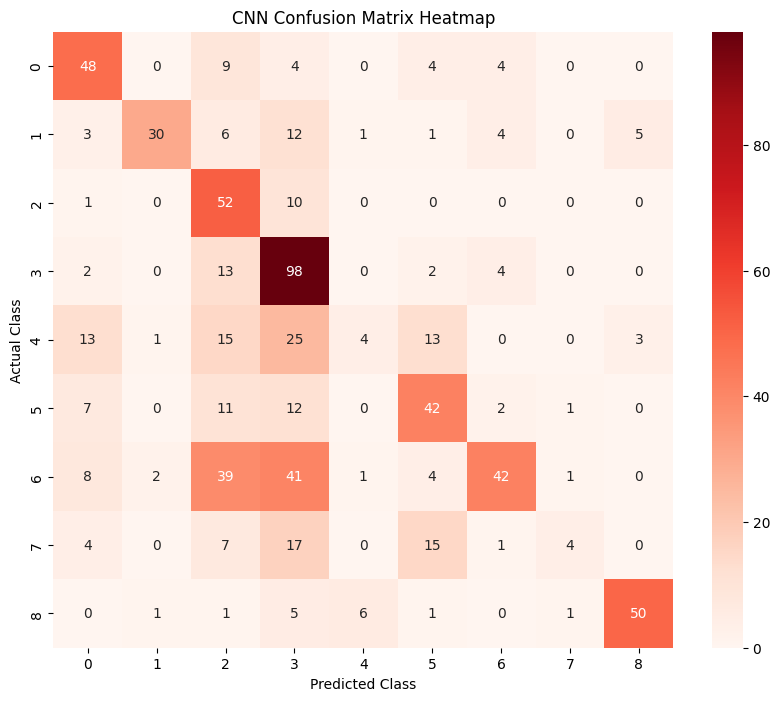

In [59]:
# Confusion Matrix heatmap on model 3 test result
cm = confusion_matrix(all_labels3, all_predictions3)

# Plot the confusion matrix as a heatmap with figsize 10 inches width wide and 8 inches tall height
plt.figure(figsize=(10, 8))

# Display prediction counts as integers in a blue heatmap, with actual and predicted class labels from 0 to 8
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", xticklabels=range(9), yticklabels=range(9))
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN Confusion Matrix Heatmap")
plt.show()

Output Explanation — CNN Model 3
Accuracy: 51.89% — How often the CNN correctly predicts the waste category. The model correctly classified 370 out of 713 test images.

Classification Report:

Precision:
- Precision (Class 0): 56% — Of all images predicted as Class 0, 56% actually belonged to Class 0.
- Precision (Class 1): 88% — Of all images predicted as Class 1, 88% actually belonged to Class 1.
- Precision (Class 2): 34% — Of all images predicted as Class 2, 34% actually belonged to Class 2.
- Precision (Class 3): 44% — Of all images predicted as Class 3, 44% actually belonged to Class 3.
- Precision (Class 4): 33% — Of all images predicted as Class 4, 33% actually belonged to Class 4.
- Precision (Class 5): 51% — Of all images predicted as Class 5, 51% actually belonged to Class 5.
- Precision (Class 6): 74% — Of all images predicted as Class 6, 74% actually belonged to Class 6.
- Precision (Class 7): 57% — Of all images predicted as Class 7, 57% actually belonged to Class 7.
- Precision (Class 8): 86% — Of all images predicted as Class 8, 86% actually belonged to Class 8.
Recall:
- Class 0: 70% — How many actual Class 0 images the model correctly identified.
- Class 1: 48% — How many actual Class 1 images the model correctly identified.
- Class 2: 83% — How many actual Class 2 images the model correctly identified.
- Class 3: 82% — How many actual Class 3 images the model correctly identified.
- Class 4: 5% — How many actual Class 4 images the model correctly identified.
- Class 5: 56% — How many actual Class 5 images the model correctly identified.
- Class 6: 30% — How many actual Class 6 images the model correctly identified.
- Class 7: 8% — How many actual Class 7 images the model correctly identified.
- Class 8: 77% — How many actual Class 8 images the model correctly identified.
F1-score:
- Class 0: 0.62 — Combined measure of precision and recall.
- Class 1: 0.62 — Combined measure of precision and recall.
- Class 2: 0.48 — Combined measure of precision and recall.
- Class 3: 0.57 — Combined measure of precision and recall.
- Class 4: 0.09 — Combined measure of precision and recall.
- Class 5: 0.54 — Combined measure of precision and recall.
- Class 6: 0.43 — Combined measure of precision and recall.
- Class 7: 0.15 — Combined measure of precision and recall.
- Class 8: 0.81 — Combined measure of precision and recall.
- Macro Average F1-score: 0.48 — Average F1-score across all nine classes, giving each class equal importance.
- Weighted Average F1-score: 0.49 — Average F1-score across all nine classes, accounting for the number of actual images in each class.
Confusion Matrix:
- Row 0: [48, 0, 9, 4, 0, 4, 4, 0, 0] — 48 out of 69 Class 0 images were correctly predicted.
- Row 1: [3, 30, 6, 12, 1, 1, 4, 0, 5] — 30 out of 62 Class 1 images were correctly predicted.
- Row 2: [1, 0, 52, 10, 0, 0, 0, 0, 0] — 52 out of 63 Class 2 images were correctly predicted.
- Row 3: [2, 0, 13, 98, 0, 2, 4, 0, 0] — 98 out of 119 Class 3 images were correctly predicted.
- Row 4: [13, 1, 15, 25, 4, 13, 0, 0, 3] — 4 out of 74 Class 4 images were correctly predicted.
- Row 5: [7, 0, 11, 12, 0, 42, 2, 1, 0] — 42 out of 75 Class 5 images were correctly predicted.
- Row 6: [8, 2, 39, 41, 1, 4, 42, 1, 0] — 42 out of 138 Class 6 images were correctly predicted.
- Row 7: [4, 0, 7, 17, 0, 15, 1, 4, 0] — 4 out of 48 Class 7 images were correctly predicted.
- Row 8: [0, 1, 1, 5, 6, 1, 0, 1, 50] — 50 out of 65 Class 8 images were correctly predicted.
Total: 370 out of 713 test images were correctly classified, giving an accuracy of 51.89%.

ROC-AUC (Receiver Operating Characteristic – Area Under the Curve)

Multiclass ROC-AUC (OvR): 0.8916 — Measures how well the CNN distinguishes each waste category from the other eight categories using prediction probabilities. A score of 0.8916 indicates good class discrimination, although the model's actual classification accuracy remains relatively low.

Compare CNN Model 2 and CNN Model 3

In [60]:
# Store accuracy for both models
accuracy2 = accuracy_score(all_labels, all_predictions)
accuracy3 = accuracy_score(all_labels3, all_predictions3)
# Store Model 2 classification report
report2 = classification_report(all_labels, all_predictions, output_dict=True)
# Store Model 3 classification report
report3 = classification_report(all_labels3, all_predictions3, output_dict=True)

# Create a DataFrame to compare both CNN models
# Weighted average: Calculates the overall precision, recall and F1-score while considering the number of test images in each class.

model_comparison = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],

    "CNN Model 2": [
        test_loss,
        accuracy2,
        report2["weighted avg"]["precision"],
        report2["weighted avg"]["recall"],
        report2["weighted avg"]["f1-score"],
        roc_auc
    ],

    "CNN Model 3": [
        epoch_test3_loss,
        accuracy3,
        report3["weighted avg"]["precision"],
        report3["weighted avg"]["recall"],
        report3["weighted avg"]["f1-score"],
        roc_auc3
    ]
})

model_comparison

,Metric,CNN Model 2,CNN Model 3
0,Test Loss,tensor(1.4756),1.428427
1,Accuracy,0.502104,0.518934
2,Precision,0.517306,0.581936
3,Recall,0.502104,0.518934
4,F1-Score,0.473862,0.485419
5,ROC-AUC,0.851018,0.891605


Confusion matrix comparison

In [61]:
# Store confusion matrices for both CNN models
cm2 = confusion_matrix(all_labels, all_predictions)
cm3 = confusion_matrix(all_labels3, all_predictions3)

# Create a DataFrame to compare both confusion matrices
confusion_comparison = pd.DataFrame({
    "Waste Category": [
        "Cardboard",
        "Food Organics",
        "Glass",
        "Metal",
        "Miscellaneous Trash",
        "Paper",
        "Plastic",
        "Textile Trash",
        "Vegetation"
    ],
    "CNN Model 2": [cm2[i, i] for i in range(9)], # Extract the number of correct predictions for each of the 9 waste categories from Model 2's confusion matrix diagonal
    "CNN Model 3": [cm3[i, i] for i in range(9)] # Extract the number of correct predictions for each of the 9 waste categories from Model 3's confusion matrix diagonal.
})

confusion_comparison

,Waste Category,CNN Model 2,CNN Model 3
0,Cardboard,33,48
1,Food Organics,32,30
2,Glass,34,52
3,Metal,62,98
4,Miscellaneous Trash,7,4
5,Paper,16,42
6,Plastic,107,42
7,Textile Trash,9,4
8,Vegetation,58,50


## 9. Improve, Train, Validate, Test, Evaluate and Compare CNN  Model 3

We are introducing data augmentation to the training dataset by applying random transformations such as horizontal flipping, rotation and colour adjustments.

Why? Our Model 3 achieved 51.89% test accuracy, and its results suggest that it struggles to recognise certain waste categories. Data augmentation helps expose the model to different variations of training images, improving its ability to recognise patterns and generalise to unseen images.

Our goal: Improve Model 3's learning, reduce overfitting and achieve better test accuracy and classification performance without altering the validation and test images.



In [62]:
# Building transformation pipeline for training images using  (data augumentation)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),  # resize images it default from 524 to 224
    transforms.RandomHorizontalFlip(p=0.5), #randomly flips an image horizontally. (by 50%)
    transforms.RandomRotation(15),#randomly rotates an image by up to 15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2), #slightly changes brightness, contrast and saturation
    transforms.ToTensor(), # Converts images into a PyTorch tensor and scales pixel values (from 0–255 to 0–1)
    transforms.Normalize(mean=[0.485, 0.456, 0.406],std=[0.229, 0.224, 0.225]) # normalized for pre-trained ViT model,(so we dont have to transform and preprocess for pretrain VITs again)
])

In [63]:
# applying data transformation pipeline recipes using pytorch wastedataset draft
train_dataset = WasteDataset(X_train, y_train, train_transform)

# Create a new DataLoader for the improved training dataset
train_loader3_impro = DataLoader(train_dataset, batch_size=32, shuffle=True)

In [64]:

import copy

epochs3_impro = 15 # Number of times the cn model3 will learn from t dataset (15 times for both train_loader and Val_loader)

patience3_impro = 3 # if validation loss fails to reach a new lowest value for 3 consecutive epochs, stop training and validating if validation loss start increasinnt

loss_func3_impro = nn.CrossEntropyLoss() #seting our crossentropyloss function (Calculate the classification error across our 9 waste categories)

optimizer3_impro = torch.optim.Adam(cnn_model3.parameters(),lr=0.001) #setting the optimizer for cnn model 3 to help us update and adjust the paramater using Adam and the learning rate 0.001

# Track the last completed epoch
start_epoch3_impro = 0

# Check if a previous checkpoint exists
if os.path.exists(MODEL3_Impro_PATH):

    # Load the saved checkpoint
    checkpoint3_impro = torch.load(MODEL3_Impro_PATH, weights_only=False)

    # Restore model and optimizer states
    cnn_model3.load_state_dict(checkpoint3_impro["model_state_dict"])
    optimizer3_impro.load_state_dict(checkpoint3_impro["optimizer_state_dict"])

    # Restore the last completed epoch and training histories
    start_epoch3_impro = checkpoint3_impro["epoch"]
    train_losses3_impro = checkpoint3_impro["train_losses"]
    val_losses3_impro = checkpoint3_impro["val_losses"]
    best_val_loss3_impro = checkpoint3_impro["best_val_loss"]
    patience_counter3_impro = checkpoint3_impro["patience_counter"]
    best_model_state_dict3_impro = checkpoint3_impro["best_model_state_dict"]

    print("Improved Model 3 checkpoint loaded!")
    print("Last completed epoch:", start_epoch3_impro)

else:

    print("No previous improved checkpoint found. Starting fresh training!")

    # Load the original Model 3 weights as the starting point
    checkpoint3_original = torch.load(MODEL3_PATH, weights_only=False)
    cnn_model3.load_state_dict(checkpoint3_original["model_state_dict"])

    train_losses3_impro = [] # Store training loss after each epoch (later be useful for visual)
    val_losses3_impro = [] # Store validation loss after each epoch (later be useful for visual)

    best_val_loss3_impro = float("inf")
    patience_counter3_impro = 0
    best_model_state_dict3_impro = copy.deepcopy(cnn_model3.state_dict())

# Resume training only if there are epochs remaining
if start_epoch3_impro < epochs3_impro and patience_counter3_impro < patience3_impro:

    # (Epoch Loop target both train and val)
    for epoch in range(start_epoch3_impro, epochs3_impro):  #for every time you go through the epochs, do it within 5 times range (loops 5 times)

        cnn_model3.train() #bring out the cnn model here for training mode
        running_train3_impro_loss = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding as the batches progress or continue within the each epochs cycle(restart from 0 again after 1 epoch cycle completed-- 0.00, )
        for images, labels in train_loader3_impro: #for every batch loss or any batch loss that keep coming, store it here and keep adding as the batches progress or continue within the each epochs cycle(restart from 0 again after 1 epoch cycle completed-- 0.00, )
            optimizer3_impro.zero_grad()  #clear the grad/gradient using backpropagation,before starting another one in new batc/epoch,
            outputs = cnn_model3(images) # all the images epoch pass through our model and produce prediction scores called logits(amount of accuracy scores for each class or labels)
            loss = loss_func3_impro(outputs, labels) # our loss function recipe work here, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss valu
            loss.backward() #Calculate gradients showing how model parameters contributed to the loss
            optimizer3_impro.step() #Adjust the model parameters using the calculated gradients( the optimizer do it works here)
            running_train3_impro_loss = running_train3_impro_loss + loss.item() * images.size(0) #(we use image.size(0) this time to get full accurate result from train_loader coz incase the last batch size isnt upto 32), (get result and convert into python num or change it from tensor to python int value .item(), then add it to the running_vtrain_loss or let say(the total of loss accumulated at end of training is our running_vtrain_loss e.g., losses of 1.2, 0.9, and 0.6 produce a total of 2.7 across three batches till the batches are fully completed and result stacks up)

        epoch_train3_impro_loss = running_train3_impro_loss / len(train_loader3_impro.dataset) # to get the loss result on each epoch cycle, scores of runing loss divide by the total len of the batch loader or the train_loader which is 104 batch (if a running loss on epoch is 150, then it would be 150/104 = 1.442, epoch loss is = 1.442), this happen like that on each epoch to the final one and the final is always the last epoch_loss scores , it also tend to reduce as epoch itetrate over and again till the last range)
        train_losses3_impro.append(epoch_train3_impro_loss) # with that result you get on epoc_train3_loss, add it as a list on var vit_training_losses


        cnn_model3.eval() #setting the cnn model 3 for validation mode
        running_val3_impro_loss = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding as the batches progress or continue within the each epochs cycle(restart from 0 again after 1 epoch cycle completed-- 0.00, )

        with torch.no_grad(): # Disable gradient calculations, We disabled gradient calculations during validation because we are evaluating the model, not training it and it serves as unseen dataset.( so no weight adjustment needed)
            for images, labels in val_loader: # Process each validation batch, every time you go through images,label in batch using(val_loader or x_val, y_val) (batch loop) (Loop through every validation batch)
                outputs = cnn_model3(images) # Generate prediction scores (logits) #all the images get validated through the model and produce prediction scores called logits(amount of accuracy scores for each class or labels)
                loss = loss_func3_impro(outputs, labels)  #Calculate the loss for the current batch, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss value or the mistakes measurement for every current batch e.g(batch 1 completed, batch 1 recorded 2.1 loss, batch 1 take the loss and go and deposit it to runing_loss, same goes for batch 2 during it turn and the rest).
                running_val3_impro_loss = running_val3_impro_loss + loss.item() * images.size(0) #(we use image.size(0) this time to get full accurate result from val_loader coz incase the last batch size isnt upto 32), (get result and convert into python num or change it from tensor to python int value .item(), then add it to the running_vval_loss or let say(the total of loss accumulated at end of training is our running_vval_loss e.g., losses of 1.2, 0.9, and 0.6 produce a total of 2.7 across three batches till the batches are fully completed and result stacks up)
        epoch_val3_impro_loss = running_val3_impro_loss / len(val_loader.dataset) #to get the loss result on validation epoch cycle, scores of total runing_loss divide by the total len of the batches, val_loader batches is 23 batch (if a running_loss scores on a single epoch is 60, then it would be 60/23 = 2.608, the epoch loss is = 1.442), this happen like that on each epoch to the final one and the final is always the last epoch_loss scores as overall , loss tend to reduce as epoch itetrate over and again till the last epoch
        val_losses3_impro.append(epoch_val3_impro_loss) # with that result you get on epoch_vval_loss, add it as a list on var vit_val_losses


        print(f"Epoch: {epoch + 1} / {epochs3_impro}") #show which current epoch out of the total epoch e.g (1/10, 2/10)
        print(f"Training Loss: {epoch_train3_impro_loss:.4f}") # show the average result of each epoch loss in rounded digit or 4 decimal e.g (1.2346, 2.0405)
        print(f"Validation Loss: {epoch_val3_impro_loss:.4f}")  #Display the final validation loss in rounded digit or 4 decimal
        print("--------------------") # Print a separator between epochs

        # Check whether validation loss has improved
        if epoch_val3_impro_loss < best_val_loss3_impro:

            best_val_loss3_impro = epoch_val3_impro_loss
            patience_counter3_impro = 0
            best_model_state_dict3_impro = copy.deepcopy(cnn_model3.state_dict())

        else:

            patience_counter3_impro = patience_counter3_impro + 1

        # Save checkpoint after each completed epoch
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": cnn_model3.state_dict(),
            "optimizer_state_dict": optimizer3_impro.state_dict(),
            "train_losses": train_losses3_impro,
            "val_losses": val_losses3_impro,
            "best_val_loss": best_val_loss3_impro,
            "patience_counter": patience_counter3_impro,
            "best_model_state_dict": best_model_state_dict3_impro
        }, MODEL3_Impro_PATH)

        print("Improved Model 3 checkpoint saved successfully!")
        print(os.path.exists(MODEL3_Impro_PATH))

        if patience_counter3_impro >= patience3_impro:
            print("Early stopping triggered!")
            break

    # Load the best model weights after training
    cnn_model3.load_state_dict(best_model_state_dict3_impro)

    # Set the model to evaluation mode after training
    cnn_model3.eval()

else:
    # Set the model to evaluation mode when all epochs are complete
    cnn_model3.load_state_dict(best_model_state_dict3_impro)
    cnn_model3.eval()
    print("Improved Model 3 loaded. Training already completed or stopped!")


Improved Model 3 checkpoint loaded!
Last completed epoch: 6
Improved Model 3 loaded. Training already completed or stopped!


In [65]:
# Load Improve Model 3 checkpoint
# Load Improved Model 3 checkpoint
checkpoint3_impro = torch.load(MODEL3_Impro_PATH, weights_only=False)

# Print Improved Model 3 training and validation losses
print("\nIMPROVED MODEL 3 TRAINING AND VALIDATION LOSSES")

for epoch, (train_loss, val_loss) in enumerate(
    zip(checkpoint3_impro["train_losses"], checkpoint3_impro["val_losses"]), start=1
):
    print(f"Epoch {epoch}: Training Loss: {train_loss:.4f} | Validation Loss: {val_loss:.4f}")


IMPROVED MODEL 3 TRAINING AND VALIDATION LOSSES
Epoch 1: Training Loss: 1.3055 | Validation Loss: 1.2619
Epoch 2: Training Loss: 1.2362 | Validation Loss: 1.1920
Epoch 3: Training Loss: 1.2185 | Validation Loss: 1.0949
Epoch 4: Training Loss: 1.2059 | Validation Loss: 1.1356
Epoch 5: Training Loss: 1.1915 | Validation Loss: 1.1500
Epoch 6: Training Loss: 1.1889 | Validation Loss: 1.1201


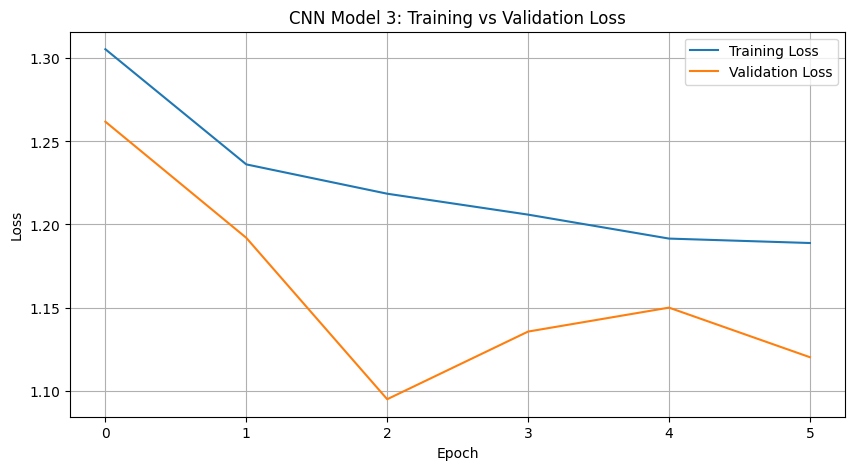

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5)) # Set the chart dimensions to 10 inches wide and 5 inches tall

plt.plot(train_losses3_impro, label="Training Loss") # Plot training loss across all 5 epoch
plt.plot(val_losses3_impro, label="Validation Loss") # Plot training loss across all 5 epoch

plt.title("CNN Model 3: Training vs Validation Loss") # title heading
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend() #Display labels identifying the training and validation results
plt.grid()
plt.show()

In [67]:
cnn_model3.eval() #Put the CNN model on evaluation mode using our cnn model and .eval()

running_test3_impro_loss = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding up till the last batch

with torch.no_grad(): # Disable gradient calculations, We disabled gradient calculations during validation because we are evaluating the model, not training it.( so no weight adjustment needed)

    for images, labels in test_loader:  #Process test_loader batch, every time you go through images,label in batch using(test_loader or x_test, y_test) (batch loop) (Loop through everytest_loader batch)

        test3_impro_output = cnn_model3(images) #Generate prediction scores (logits) #all the images get validated through the model and produce prediction scores called logits(amount of accuracy scores for each class or labels)

        test3_impro_loss = loss_func3_impro(test3_impro_output, labels) #Calculate the loss for the current batch, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss value or the mistakes measurement for every current batch e.g(batch 1 completed, batch 1 recorded 2.1 loss, batch 1 take the loss and go and deposit it to runing_loss, same goes for batch 2 during it turn and the rest).

        running_test3_impro_loss = running_test3_impro_loss + test3_impro_loss.item()* images.size(0) # Convert the batch loss tensor to a Python number, multiply by the number of images(we use image this time to full accurate result from test_loader coz incase the last batch size isnt upto 32) in the current batch to get the total batch loss, and add it to the accumulated test loss

epoch_test3_impro_loss = running_test3_impro_loss / len(test_loader.dataset) # Divide the accumulated test loss by the total number of test images to calculate the average test loss

print(f"Improved Model 3 Test Loss: {epoch_test3_impro_loss:.4f}") #Display the final Test loss in rounded digit or 4 decimal

Improved Model 3 Test Loss: 1.0896


In [68]:
correct3_impro = 0  # Count correctly classified images (all correct image count stay inside here)
total3_impro = 0  # Count all tested images (all total image being tested stay inside here)

with torch.no_grad():  # Disable gradient calculations during testing
    for images, labels in test_loader:  #Loop through batches of test images
        outputs3_impro = cnn_model3(images)  #Generate predictions logits\logits  for the current batch (amount of higest accuracy scores for each class or labels e.g this image is on label 7, and logits bring out all the scores for the whole 9 label, whichever have the highest score is consider true here, even if it is wrong)

        predicted3_impro = torch.argmax(outputs3_impro, dim=1)  #Get the index of the highest prediction/logits score for each image (e.g. [0.2, 0.5, 1.8, 0.3] → class index 2 is the highest which is 1.8)

        total3_impro = total3_impro + len(images) # Get the actual number of images count in the current batch and add it to the variable total till the final images (e.g 32+ 32 + 32 + 16 = 112 images)

        correct3_impro = correct3_impro + (predicted3_impro == labels).sum().item() # Compare predicted classes with actual labels classes, and sum up the correct predictions after counting, convert the count to a Python number, and add it to the variable correct for each batches

test3_impro_accuracy = 100 * correct3_impro / total3_impro  # store this math in a var called test_accuracy by using correct var divide by total var and round it in percentage e,g(1600/3000 = 0.5333 which is 53.33%)

print(f"Correct Predictions: {correct3_impro}/{total3_impro}")  # show result both correct and total variable (stacking o n each other 358/713)
print(f"Test Accuracy: {test3_impro_accuracy:.2f}%")  # Display value of var test_accuracy

Correct Predictions: 451/713
Test Accuracy: 63.25%


The CNN model 3 correctly classified 451 out of 713 test images, achieving an accuracy of 63.25%. This means the model correctly identified approximately half of the unseen waste images

In [69]:
all_predictions3_impro = []  # Store the model's predicted class index for every test image
all_labels3_impro = []  # Store the actual class index for every test image
all_probabilities3_impro = []  # Store the predicted probabilities for all 9 classes (for ROC-AUC)

cnn_model3.eval()  # Set the CNN to evaluation mode

with torch.no_grad():  #Disable gradient calculations during testing
    for images, labels in test_loader:  #loop througb image and label for each batches in loader

        outputs3_impro = cnn_model3(images)  ##Generate predictions logits\logits  for the current batch (amount of higest accuracy scores for each class or labels e.g this image is on label 7, and logits bring out all the scores for the whole 9 label, whichever have the highest score is consider true here, even if it is wrong)

        predicted3_impro = torch.argmax(outputs3_impro, dim=1) #Get the index of the highest prediction/logits score for each image (e.g. [0.2, 0.5, 1.8, 0.3] → class index 2 is the highest which is 1.8)
        Probabilities3_impro = torch.softmax(outputs3_impro, dim=1)  #Convert logits into probabilities for the 9 classes (we use torch.softmax() to convert the model's raw outputs (logits) into probabilities)

        all_predictions3_impro.extend(predicted3_impro.cpu().tolist()) # change result from GPU to CPU incase, Convert batch predictions to a Python list(away from tensor) and add each predicted class index to all_predictions var list that was created above (e.g 6, 1, 3, 8,8 )
        all_labels3_impro.extend(labels.cpu().tolist())  # change result from GPU to CPU incase, Convert batch actual class/label to a Python list(away from tensor) and add each label/class index to all_labels var list that was created above (e.g class 0, 1, 5, 2, 3)
        all_probabilities3_impro.extend(Probabilities3_impro.cpu().tolist())  # Store probability scores for every image, convert probabilities to a Python list(away from tensor)

In [70]:
print("All Predictions:", all_predictions3_impro[:10])  #  show the first 10 predicted class to see
print("Actual Labels:", all_labels3_impro[:10])  #show the first 10 actual class to see if they match
print("All Probabilities:", all_probabilities3_impro[:10])  #  show the first 10 probabilities to see

print("Total Predictions:", len(all_predictions3_impro))  # Count all predictions collected
print("Total Labels:", len(all_labels3_impro))  # Count all actual labels collected, expect same count on both
print("Total Probabilities:",len(all_probabilities3_impro))  # Count all probabilities collect

All Predictions: [6, 1, 3, 8, 8, 6, 6, 3, 6, 6]
Actual Labels: [2, 1, 3, 8, 8, 5, 0, 3, 6, 0]
All Probabilities: [[0.005423841066658497, 0.0014647237258031964, 0.20405107736587524, 0.20655971765518188, 0.10833709686994553, 0.06021999940276146, 0.23007646203041077, 0.1804676502943039, 0.003399414476007223], [0.02195345237851143, 0.751515805721283, 0.009696973487734795, 0.039610520005226135, 0.04090208187699318, 0.011444715782999992, 0.013034227304160595, 0.013832716271281242, 0.09800947457551956], [0.010837970301508904, 5.86144087719731e-05, 0.036880653351545334, 0.45546066761016846, 0.11963483691215515, 0.016883445903658867, 0.2685914933681488, 0.0906149297952652, 0.0010374132543802261], [0.0002121686120517552, 0.06538869440555573, 0.00040505119250155985, 0.002813035622239113, 0.007675112225115299, 0.0003005658509209752, 0.000249387783696875, 0.003212420269846916, 0.9197434782981873], [0.00010793961700983346, 0.009846524335443974, 2.202426685471437e-07, 7.19428644515574e-05, 9.76115261

In [71]:
# to get better view on table of our all predictions and all labels and all probabilities we just retrieved in above cell, lets create table consisting each column using pd.frame
results3_df_impro = pd.DataFrame({"Actual Labels": all_labels3_impro,"Predicted Labels": all_predictions3_impro,"Probabilities": all_probabilities3_impro})

# show result
results3_df_impro

,Actual Labels,Predicted Labels,Probabilities
0,2,6,"[0.005423841066658497, 0.0014647237258031964, ..."
1,1,1,"[0.02195345237851143, 0.751515805721283, 0.009..."
2,3,3,"[0.010837970301508904, 5.86144087719731e-05, 0..."
3,8,8,"[0.0002121686120517552, 0.06538869440555573, 0..."
4,8,8,"[0.00010793961700983346, 0.009846524335443974,..."
...,...,...,...
708,1,6,"[0.04608260467648506, 0.2771131694316864, 0.08..."
709,1,1,"[0.08228830248117447, 0.45181572437286377, 0.0..."
710,4,6,"[0.00088403036352247, 0.0007523192325606942, 0..."
711,7,8,"[0.015280263498425484, 0.1416579782962799, 0.0..."


Classification performance using accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC on CNN model 3 improved test_loader results3

In [72]:
# Import evaluation metrics, the 4 metrics are (accuracy_score, classification_report, confusion_matrix, roc_auc_score)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

In [73]:
# Print the Evaluate predictions for Accuracy Metrics
print("Accuracy:", accuracy_score(all_labels3_impro, all_predictions3_impro))

#Print the Evaluate predictions for Classifications Report
print("\nClassification Report:")
print(classification_report(all_labels3_impro, all_predictions3_impro))

#Print the Evaluate predictions for Confusion Matrix metrics
print("\nConfusion Matrix:")
print(confusion_matrix(all_labels3_impro, all_predictions3_impro))

#Print the Evaluate predictions for ROC_AUC
roc_auc3_impro = roc_auc_score(all_labels3_impro, all_probabilities3_impro, multi_class="ovr", average="macro") # Compare each class against the remaining 8 classes (=ovr means One-vs-Rest) and Calculate the average ROC-AUC across all 9 classes
print("\nMulticlass ROC-AUC (OvR):", round(roc_auc3_impro, 4))

Accuracy: 0.6325385694249649

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.65      0.68        69
           1       0.80      0.76      0.78        62
           2       0.73      0.70      0.72        63
           3       0.76      0.54      0.63       119
           4       0.38      0.11      0.17        74
           5       0.63      0.53      0.58        75
           6       0.52      0.86      0.65       138
           7       0.44      0.54      0.49        48
           8       0.77      0.91      0.83        65

    accuracy                           0.63       713
   macro avg       0.64      0.62      0.61       713
weighted avg       0.64      0.63      0.61       713


Confusion Matrix:
[[ 45   2   2   0   1   7  11   0   1]
 [  1  47   0   1   1   1   6   0   5]
 [  3   0  44   2   0   0  11   3   0]
 [  0   1   3  64   6   6  36   3   0]
 [  4   3   2   6   8   2  25  15   9]
 [  8   0   6   5   1  40  1

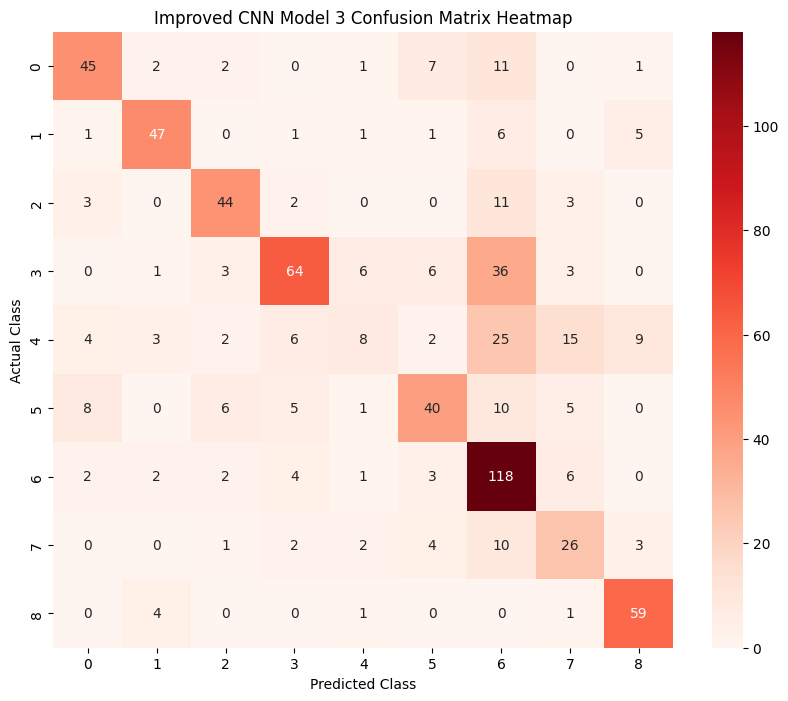

In [74]:
# Confusion Matrix heatmap on model 3 test result
cm3_impro = confusion_matrix(all_labels3_impro, all_predictions3_impro)

# Plot the confusion matrix as a heatmap with figsize 10 inches width wide and 8 inches tall height
plt.figure(figsize=(10, 8))

# Display prediction counts as integers in a blue heatmap, with actual and predicted class labels from 0 to 8
sns.heatmap(cm3_impro, annot=True, fmt="d", cmap="Reds", xticklabels=range(9), yticklabels=range(9))
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Improved CNN Model 3 Confusion Matrix Heatmap")
plt.show()

Output Explanation — Improved CNN Model 3
Accuracy: 63.25% — Measures how often the CNN correctly predicts the waste category. The model correctly classified 451 out of 713 test images.

Classification Report
Precision:
- Precision (Class 0): 71% — Of all images predicted as Class 0, 71% actually belonged to Class 0.
- Precision (Class 1): 80% — Of all images predicted as Class 1, 80% actually belonged to Class 1.
- Precision (Class 2): 73% — Of all images predicted as Class 2, 73% actually belonged to Class 2.
- Precision (Class 3): 76% — Of all images predicted as Class 3, 76% actually belonged to Class 3.
- Precision (Class 4): 38% — Of all images predicted as Class 4, 38% actually belonged to Class 4.
- Precision (Class 5): 63% — Of all images predicted as Class 5, 63% actually belonged to Class 5.
- Precision (Class 6): 52% — Of all images predicted as Class 6, 52% actually belonged to Class 6.
- Precision (Class 7): 44% — Of all images predicted as Class 7, 44% actually belonged to Class 7.
- Precision (Class 8): 77% — Of all images predicted as Class 8, 77% actually belonged to Class 8.

Recall:
- Class 0: 65% — The model correctly identified 65% of all actual Class 0 images.
- Class 1: 76% — The model correctly identified 76% of all actual Class 1 images.
- Class 2: 70% — The model correctly identified 70% of all actual Class 2 images.
- Class 3: 54% — The model correctly identified 54% of all actual Class 3 images.
- Class 4: 11% — The model correctly identified 11% of all actual Class 4 images.
- Class 5: 53% — The model correctly identified 53% of all actual Class 5 images.
- Class 6: 86% — The model correctly identified 86% of all actual Class 6 images.
- Class 7: 54% — The model correctly identified 54% of all actual Class 7 images.
- Class 8: 91% — The model correctly identified 91% of all actual Class 8 images.

F1-score:
- Class 0: 0.68 — Combined measure of precision and recall.
- Class 1: 0.78 — Combined measure of precision and recall.
- Class 2: 0.72 — Combined measure of precision and recall.
- Class 3: 0.63 — Combined measure of precision and recall.
- Class 4: 0.17 — Combined measure of precision and recall.
- Class 5: 0.58 — Combined measure of precision and recall.
- Class 6: 0.65 — Combined measure of precision and recall.
- Class 7: 0.49 — Combined measure of precision and recall.
- Class 8: 0.83 — Combined measure of precision and recall.

- Macro Average F1-score: 0.61 — Average F1-score across all nine classes, giving each class equal importance.

- Weighted Average F1-score: 0.61 — Average F1-score across all nine classes, accounting for the number of actual images in each class.

Confusion Matrix
Each row represents the actual waste category, while each column represents the category predicted by the model. The diagonal values represent correct predictions.

- Row 0: [45, 2, 2, 0, 1, 7, 11, 0, 1] — 45 out of 69 Class 0 images were correctly predicted.
- Row 1: [1, 47, 0, 1, 1, 1, 6, 0, 5] — 47 out of 62 Class 1 images were correctly predicted.
- Row 2: [3, 0, 44, 2, 0, 0, 11, 3, 0] — 44 out of 63 Class 2 images were correctly predicted.
- Row 3: [0, 1, 3, 64, 6, 6, 36, 3, 0] — 64 out of 119 Class 3 images were correctly predicted.
- Row 4: [4, 3, 2, 6, 8, 2, 25, 15, 9] — 8 out of 74 Class 4 images were correctly predicted.
- Row 5: [8, 0, 6, 5, 1, 40, 10, 5, 0] — 40 out of 75 Class 5 images were correctly predicted.
- Row 6: [2, 2, 2, 4, 1, 3, 118, 6, 0] — 118 out of 138 Class 6 images were correctly predicted.
- Row 7: [0, 0, 1, 2, 2, 4, 10, 26, 3] — 26 out of 48 Class 7 images were correctly predicted.
- Row 8: [0, 4, 0, 0, 1, 0, 0, 1, 59] — 59 out of 65 Class 8 images were correctly predicted.

Total: 451 out of 713 test images were correctly classified, giving an accuracy of 63.25%.

ROC-AUC (Receiver Operating Characteristic – Area Under the Curve)
Multiclass ROC-AUC (OvR): 0.9221 — Measures how well the CNN distinguishes each waste category from the other eight categories using prediction probabilities.
A score of 0.9221 indicates strong class discrimination, although this does not mean the model has 92.21% classification accuracy.

Overall Evaluation
Improved CNN Model 3 performed better than the original CNN Model 3. Its accuracy increased from 51.89% to 63.25%, while its macro F1-score increased from 0.48 to 0.61 and ROC-AUC increased from 0.8916 to 0.9221.

Compare CNN model 3 vs Improved CNN model 3

In [75]:
# Store accuracy for both models
accuracy3 = accuracy_score(all_labels3, all_predictions3)
accuracy3_impro = accuracy_score(all_labels3_impro, all_predictions3_impro)

# Store Model 3 classification report
report3 = classification_report(all_labels3, all_predictions3, output_dict=True)

# Store Improved Model 3 classification report
report3_impro = classification_report(all_labels3_impro, all_predictions3_impro, output_dict=True)

# Create a DataFrame to compare both CNN models
# Weighted average: Calculates the overall precision, recall and F1-score while considering the number of test images in each class.

model_comparison3 = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],

    "CNN Model 3": [
        epoch_test3_loss,
        accuracy3,
        report3["weighted avg"]["precision"],
        report3["weighted avg"]["recall"],
        report3["weighted avg"]["f1-score"],
        roc_auc3
    ],

    "Improved CNN Model 3": [
        epoch_test3_impro_loss,
        accuracy3_impro,
        report3_impro["weighted avg"]["precision"],
        report3_impro["weighted avg"]["recall"],
        report3_impro["weighted avg"]["f1-score"],
        roc_auc3_impro
    ]
})

model_comparison3

,Metric,CNN Model 3,Improved CNN Model 3
0,Test Loss,1.428427,1.089569
1,Accuracy,0.518934,0.632539
2,Precision,0.581936,0.636809
3,Recall,0.518934,0.632539
4,F1-Score,0.485419,0.614065
5,ROC-AUC,0.891605,0.922105


In [76]:
# Store confusion matrices for both CNN models
cm3 = confusion_matrix(all_labels3, all_predictions3)
cm3_impro = confusion_matrix(all_labels3_impro, all_predictions3_impro)

# Create a DataFrame to compare both confusion matrices
confusion_comparison3 = pd.DataFrame({
    "Waste Category": [
        "Cardboard",
        "Food Organics",
        "Glass",
        "Metal",
        "Miscellaneous Trash",
        "Paper",
        "Plastic",
        "Textile Trash",
        "Vegetation"
    ],
    "CNN Model 3": [cm3[i, i] for i in range(9)], # Extract the number of correct predictions for each of the 9 waste categories from Model 3's confusion matrix diagonal
    "Improved CNN Model 3": [cm3_impro[i, i] for i in range(9)] # Extract the number of correct predictions for each of the 9 waste categories from Improved Model 3's confusion matrix diagonal.
})

confusion_comparison3

,Waste Category,CNN Model 3,Improved CNN Model 3
0,Cardboard,48,45
1,Food Organics,30,47
2,Glass,52,44
3,Metal,98,64
4,Miscellaneous Trash,4,8
5,Paper,42,40
6,Plastic,42,118
7,Textile Trash,4,26
8,Vegetation,50,59


In [77]:
# Define the path for the final selected CNN model
FINAL_MODEL3_PATH = os.path.join(CHECKPOINT_DIR, 'final_cnn_model3.pth')

# Load the Improved Model 3 checkpoint
checkpoint3_impro = torch.load(MODEL3_Impro_PATH, weights_only=False)

# Load the best model weights from the improved checkpoint
cnn_model3.load_state_dict(checkpoint3_impro["best_model_state_dict"])

# Set the final CNN model to evaluation mode
cnn_model3.eval()

# Save the best Improved Model 3 weights as the final CNN model
torch.save(cnn_model3.state_dict(), FINAL_MODEL3_PATH)

# Load the saved final model weights to verify the checkpoint
cnn_model3.load_state_dict(torch.load(FINAL_MODEL3_PATH, weights_only=True))

print("Final CNN Model 3 saved and verified successfully!")
print("Checkpoint path:", FINAL_MODEL3_PATH)

Final CNN Model 3 saved and verified successfully!
Checkpoint path: /content/drive/MyDrive/Smart Waste Recognition AI/colab_models/final_cnn_model3.pth


In [78]:
# Check if the Improved CNN Model 3 checkpoint exists
if os.path.exists(MODEL3_Impro_PATH):

    print("Improved CNN Model 3 checkpoint found!")
    print("Checkpoint path:", MODEL3_Impro_PATH)

    # Load the checkpoint
    checkpoint3_impro = torch.load(MODEL3_Impro_PATH, weights_only=False)

    # Display the checkpoint information
    print("\nCheckpoint contents:")
    print(checkpoint3_impro.keys())

    print("\nCompleted epochs:", checkpoint3_impro["epoch"])
    print("Best validation loss:", checkpoint3_impro["best_val_loss"])

    print("\nTraining losses:", checkpoint3_impro["train_losses"])
    print("Validation losses:", checkpoint3_impro["val_losses"])

    print("\nBest model weights available:",
          "best_model_state_dict" in checkpoint3_impro)

else:
    print("No Improved CNN Model 3 checkpoint found!")

Improved CNN Model 3 checkpoint found!
Checkpoint path: /content/drive/MyDrive/Smart Waste Recognition AI/colab_models/cnn_model3_imp.pth

Checkpoint contents:
dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_losses', 'val_losses', 'best_val_loss', 'patience_counter', 'best_model_state_dict'])

Completed epochs: 6
Best validation loss: 1.094863794127487

Training losses: [1.3054693011153697, 1.2361723703572496, 1.218528502760203, 1.2059415259134747, 1.1915244018178495, 1.188859714274656]
Validation losses: [1.2618544223766675, 1.191975841933514, 1.094863794127487, 1.1355746173591132, 1.1499762916297431, 1.1201414213441365]

Best model weights available: True


In [79]:
# Load the best Improved CNN Model 3 checkpoint
cnn_model3.load_state_dict(checkpoint3_impro["best_model_state_dict"])

# Set the model to evaluation mode
cnn_model3.eval()

print("Best Improved CNN Model 3 weights loaded successfully!")

Best Improved CNN Model 3 weights loaded successfully!


## 10. Fine-Tune Improved CNN Model 3, Train, Validate, Test, Evaluate, Compare and Select the Final Model

Fine-Tuning Improved CNN Model 3

In this experiment, we will fine-tune the existing Improved CNN Model 3 using its best saved weights from Epoch 3. We will reduce the learning rate from 0.001 to 0.0001 to allow the model to make smaller adjustments to its learned parameters.

In [80]:
# Set the fine-tuning parameters
epochs3_fine = 15
patience3_fine = 3

# Define the loss function
loss_func3_fine = nn.CrossEntropyLoss()

# Create a new optimizer with a lower learning rate
optimizer3_fine = torch.optim.Adam(cnn_model3.parameters(), lr=0.0001)

# Define a separate checkpoint path for fine-tuning
MODEL3_Fine_PATH = os.path.join(CHECKPOINT_DIR, 'cnn_model3_fine.pth')

# Initialise training and validation losses
train_losses3_fine = []
val_losses3_fine = []

# Initialise early stopping variables
best_val_loss3_fine = float("inf")
patience_counter3_fine = 0

# Save the initial best model weights
best_model_state3_fine = copy.deepcopy(cnn_model3.state_dict())

print("Fine-tuning settings initialised successfully!")

Fine-tuning settings initialised successfully!


In [81]:
# Track the last completed epoch
start_epoch3_fine = 0

# Check if a previous checkpoint exists
if os.path.exists(MODEL3_Fine_PATH):

    # Load the saved checkpoint
    checkpoint3_fine = torch.load(MODEL3_Fine_PATH, weights_only=False)

    # Restore model and optimizer states
    cnn_model3.load_state_dict(checkpoint3_fine["model_state_dict"])
    optimizer3_fine.load_state_dict(checkpoint3_fine["optimizer_state_dict"])

    # Restore the last completed epoch and training histories
    start_epoch3_fine = checkpoint3_fine["epoch"]
    train_losses3_fine = checkpoint3_fine["train_losses"]
    val_losses3_fine = checkpoint3_fine["val_losses"]
    best_val_loss3_fine = checkpoint3_fine["best_val_loss"]
    patience_counter3_fine = checkpoint3_fine["patience_counter"]
    best_model_state3_fine = checkpoint3_fine["best_model_state_dict"]

    print("Saved fine-tuning checkpoint loaded!")
    print("Last completed epoch:", start_epoch3_fine)

else:

    print("No previous fine-tuning checkpoint found. Starting fresh training!")

    train_losses3_fine = [] # Store training loss after each epoch (later be useful for visual)
    val_losses3_fine = [] # Store validation loss after each epoch (later be useful for visual)

# Resume training only if there are epochs remaining
if start_epoch3_fine < epochs3_fine:

    # (Epoch Loop target both train and val)
    for epoch in range(start_epoch3_fine, epochs3_fine):  #for every time you go through the epochs, do it within 5 times range (loops 5 times)

        cnn_model3.train() #bring out the cnn model here for training mode
        running_train3_fine = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding as the batches progress or continue within the each epochs cycle(restart from 0 again after 1 epoch cycle completed-- 0.00, )
        for images, labels in train_loader3_impro: #for every batch loss or any batch loss that keep coming, store it here and keep adding as the batches progress or continue within the each epochs cycle(restart from 0 again after 1 epoch cycle completed-- 0.00, )
            optimizer3_fine.zero_grad()  #clear the grad/gradient using backpropagation,before starting another one in new batc/epoch,
            outputs = cnn_model3(images) # all the images epoch pass through our model and produce prediction scores called logits(amount of accuracy scores for each class or labels)
            loss = loss_func3_fine(outputs, labels) # our loss function recipe work here, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss valu
            loss.backward() #Calculate gradients showing how model parameters contributed to the loss
            optimizer3_fine.step() #Adjust the model parameters using the calculated gradients( the optimizer do it works here)
            running_train3_fine = running_train3_fine + loss.item() * images.size(0) #(we use image.size(0) this time to get full accurate result from train_loader coz incase the last batch size isnt upto 32), (get result and convert into python num or change it from tensor to python int value .item(), then add it to the running_vtrain_loss or let say(the total of loss accumulated at end of training is our running_vtrain_loss e.g., losses of 1.2, 0.9, and 0.6 produce a total of 2.7 across three batches till the batches are fully completed and result stacks up)

        epoch_train3_fine = running_train3_fine / len(train_loader3_impro.dataset) # to get the loss result on each epoch cycle, scores of runing loss divide by the total len of the batch loader or the train_loader which is 104 batch (if a running loss on epoch is 150, then it would be 150/104 = 1.442, epoch loss is = 1.442), this happen like that on each epoch to the final one and the final is always the last epoch_loss scores , it also tend to reduce as epoch itetrate over and again till the last range)
        train_losses3_fine.append(epoch_train3_fine) # with that result you get on epoc_train3_loss, add it as a list on var vit_training_losses


        cnn_model3.eval() #setting the cnn model 3 for validation mode
        running_val3_fine = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding as the batches progress or continue within the each epochs cycle(restart from 0 again after 1 epoch cycle completed-- 0.00, )

        with torch.no_grad(): # Disable gradient calculations, We disabled gradient calculations during validation because we are evaluating the model, not training it and it serves as unseen dataset.( so no weight adjustment needed)
            for images, labels in val_loader: # Process each validation batch, every time you go through images,label in batch using(val_loader or x_val, y_val) (batch loop) (Loop through every validation batch)
                outputs = cnn_model3(images) # Generate prediction scores (logits) #all the images get validated through the model and produce prediction scores called logits(amount of accuracy scores for each class or labels)
                loss = loss_func3_fine(outputs, labels)  #Calculate the loss for the current batch, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss value or the mistakes measurement for every current batch e.g(batch 1 completed, batch 1 recorded 2.1 loss, batch 1 take the loss and go and deposit it to runing_loss, same goes for batch 2 during it turn and the rest).
                running_val3_fine = running_val3_fine + loss.item() * images.size(0) #(we use image.size(0) this time to get full accurate result from val_loader coz incase the last batch size isnt upto 32), (get result and convert into python num or change it from tensor to python int value .item(), then add it to the running_vval_loss or let say(the total of loss accumulated at end of training is our running_vval_loss e.g., losses of 1.2, 0.9, and 0.6 produce a total of 2.7 across three batches till the batches are fully completed and result stacks up)
        epoch_val3_fine = running_val3_fine / len(val_loader.dataset) #to get the loss result on validation epoch cycle, scores of total runing_loss divide by the total len of the batches, val_loader batches is 23 batch (if a running_loss scores on a single epoch is 60, then it would be 60/23 = 2.608, the epoch loss is = 1.442), this happen like that on each epoch to the final one and the final is always the last epoch_loss scores as overall , loss tend to reduce as epoch itetrate over and again till the last epoch
        val_losses3_fine.append(epoch_val3_fine) # with that result you get on epoch_vval_loss, add it as a list on var vit_val_losses

        # Check if validation loss has improved
        if epoch_val3_fine < best_val_loss3_fine:
            best_val_loss3_fine = epoch_val3_fine
            patience_counter3_fine = 0
            best_model_state3_fine = copy.deepcopy(cnn_model3.state_dict())

        else:
            patience_counter3_fine = patience_counter3_fine + 1


        print(f"Epoch: {epoch + 1} / {epochs3_fine}") #show which current epoch out of the total epoch e.g (1/10, 2/10)
        print(f"Training Loss: {epoch_train3_fine:.4f}") # show the average result of each epoch loss in rounded digit or 4 decimal e.g (1.2346, 2.0405)
        print(f"Validation Loss: {epoch_val3_fine:.4f}")  #Display the final validation loss in rounded digit or 4 decimal
        print(f"Best Validation Loss: {best_val_loss3_fine:.4f}")
        print("--------------------") # Print a separator between epochs

        # Save checkpoint after each completed epoch
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": cnn_model3.state_dict(),
            "optimizer_state_dict": optimizer3_fine.state_dict(),
            "train_losses": train_losses3_fine,
            "val_losses": val_losses3_fine,
            "best_val_loss": best_val_loss3_fine,
            "patience_counter": patience_counter3_fine,
            "best_model_state_dict": best_model_state3_fine
        }, MODEL3_Fine_PATH)

        print("Fine-tuning checkpoint saved successfully!")
        print(os.path.exists(MODEL3_Fine_PATH))

        # Stop training if validation loss fails to improve for 3 consecutive epochs
        if patience_counter3_fine >= patience3_fine:
            print("Early stopping triggered!")
            break

    # Load the best model weights after training
    cnn_model3.load_state_dict(best_model_state3_fine)

    # Set the model to evaluation mode after training
    cnn_model3.eval()

else:
    # Load the best model weights when all epochs are complete
    cnn_model3.load_state_dict(best_model_state3_fine)

    # Set the model to evaluation mode when all epochs are complete
    cnn_model3.eval()
    print("Saved fine-tuned model loaded. Training already completed!")

Saved fine-tuning checkpoint loaded!
Last completed epoch: 15
Saved fine-tuned model loaded. Training already completed!


In [82]:
# Load Fine-Tuned Model 3 checkpoint
checkpoint3_fine = torch.load(MODEL3_Fine_PATH, weights_only=False)

# Print Fine-Tuned Model 3 training and validation losses
print("\nFINE-TUNED MODEL 3 TRAINING AND VALIDATION LOSSES")

for epoch, (train_loss, val_loss) in enumerate(
    zip(checkpoint3_fine["train_losses"], checkpoint3_fine["val_losses"]), start=1
):
    print(f"Epoch {epoch}: Training Loss: {train_loss:.4f} | Validation Loss: {val_loss:.4f}")


FINE-TUNED MODEL 3 TRAINING AND VALIDATION LOSSES
Epoch 1: Training Loss: 1.1603 | Validation Loss: 1.0359
Epoch 2: Training Loss: 1.1458 | Validation Loss: 1.0445
Epoch 3: Training Loss: 1.1471 | Validation Loss: 1.0565
Epoch 4: Training Loss: 1.1349 | Validation Loss: 1.0288
Epoch 5: Training Loss: 1.1133 | Validation Loss: 1.0148
Epoch 6: Training Loss: 1.1077 | Validation Loss: 0.9973
Epoch 7: Training Loss: 1.1186 | Validation Loss: 1.0051
Epoch 8: Training Loss: 1.1013 | Validation Loss: 0.9951
Epoch 9: Training Loss: 1.1100 | Validation Loss: 0.9926
Epoch 10: Training Loss: 1.0974 | Validation Loss: 0.9991
Epoch 11: Training Loss: 1.1053 | Validation Loss: 1.0320
Epoch 12: Training Loss: 1.0981 | Validation Loss: 1.0395
Epoch 13: Training Loss: 1.0888 | Validation Loss: 0.9840
Epoch 14: Training Loss: 1.0939 | Validation Loss: 1.0213
Epoch 15: Training Loss: 1.0975 | Validation Loss: 1.0214


In [83]:
# saving epoch 9 as our selected model, ensure we load the whole model here
cnn_model3.load_state_dict(checkpoint3_fine["best_model_state_dict"])

<All keys matched successfully>

Lets visualize how the fine tuning model behave across  between train_loader and val_loader using line chart

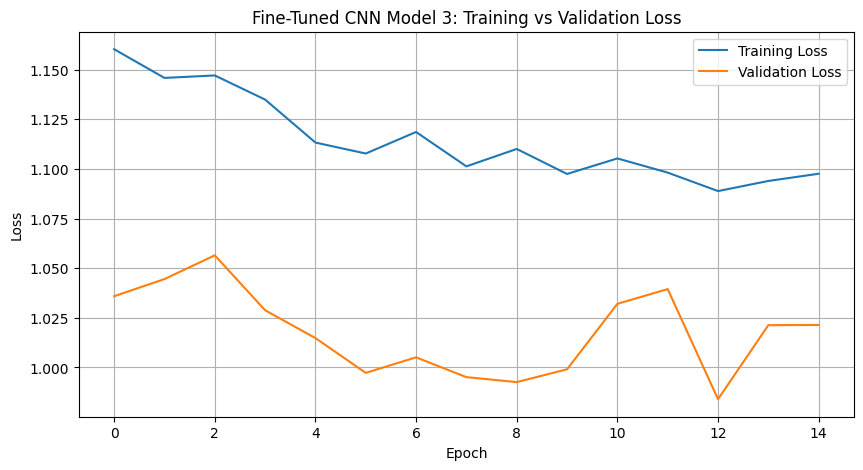

In [84]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5)) # Set the chart dimensions to 10 inches wide and 5 inches tall

plt.plot(train_losses3_fine, label="Training Loss") # Plot training loss across all 12 epochs
plt.plot(val_losses3_fine, label="Validation Loss") # Plot validation loss across all 12 epochs

plt.title("Fine-Tuned CNN Model 3: Training vs Validation Loss") # title heading
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend() #Display labels identifying the training and validation results
plt.grid()
plt.show()

In [85]:
cnn_model3.eval() #Put the CNN model on evaluation mode using our cnn model and .eval()

running_test3_fine_loss = 0.0 #for every batch loss or any batch loss that keep coming, store it here and keep adding up till the last batch

with torch.no_grad(): # Disable gradient calculations, We disabled gradient calculations during validation because we are evaluating the model, not training it.( so no weight adjustment needed)

    for images, labels in test_loader:  #Process test_loader batch, every time you go through images,label in batch using(test_loader or x_test, y_test) (batch loop) (Loop through everytest_loader batch)

        test3_fine_output = cnn_model3(images) #Generate prediction scores (logits) #all the images get validated through the model and produce prediction scores called logits(amount of accuracy scores for each class or labels)

        test3_fine_loss = loss_func3_fine(test3_fine_output, labels) #Calculate the loss for the current batch, compare the prediction scores/logits across the actual labels or (get the mistakes measurement),then calculates the loss value or the mistakes measurement for every current batch e.g(batch 1 completed, batch 1 recorded 2.1 loss, batch 1 take the loss and go and deposit it to runing_loss, same goes for batch 2 during it turn and the rest).

        running_test3_fine_loss = running_test3_fine_loss + test3_fine_loss.item()* images.size(0) # Convert the batch loss tensor to a Python number, multiply by the number of images(we use image this time to full accurate result from test_loader coz incase the last batch size isnt upto 32) in the current batch to get the total batch loss, and add it to the accumulated test loss

epoch_test3_fine_loss = running_test3_fine_loss / len(test_loader.dataset) # Divide the accumulated test loss by the total number of test images to calculate the average test loss

print(f"Fine-Tuned CNN Model 3 Test Loss: {epoch_test3_fine_loss:.4f}") #Display the final Test loss in rounded digit or 4 decimal

Fine-Tuned CNN Model 3 Test Loss: 0.9786


In [86]:
correct3_fine = 0  # Count correctly classified images (all correct image count stay inside here)
total3_fine = 0  # Count all tested images (all total image being tested stay inside here)

with torch.no_grad():  # Disable gradient calculations during testing
    for images, labels in test_loader:  #Loop through batches of test images
        outputs3_fine = cnn_model3(images)  #Generate prediction logits for the current batch (amount of highest prediction scores for each class or labels e.g this image is on label 7, and logits bring out all the scores for the whole 9 label, whichever has the highest score is considered the predicted class, even if it is wrong)

        predicted3_fine = torch.argmax(outputs3_fine, dim=1)  #Get the index of the highest prediction/logits score for each image (e.g. [0.2, 0.5, 1.8, 0.3] → class index 2 is the highest which is 1.8)

        total3_fine = total3_fine + len(images) # Get the actual number of images count in the current batch and add it to the variable total till the final images (e.g 32+ 32 + 32 + 16 = 112 images)

        correct3_fine = correct3_fine + (predicted3_fine == labels).sum().item() # Compare predicted classes with actual labels classes, and sum up the correct predictions after counting, convert the count to a Python number, and add it to the variable correct for each batches

test3_fine_accuracy = 100 * correct3_fine / total3_fine  # store this math in a var called test_accuracy by using correct var divide by total var and round it in percentage e,g(1600/3000 = 0.5333 which is 53.33%)

print(f"Correct Predictions: {correct3_fine}/{total3_fine}")  # show result both correct and total variable (stacking o n each other 358/713)
print(f"Fine-Tuned CNN Model 3 Test Accuracy: {test3_fine_accuracy:.2f}%")  # Display value of var test_accuracy

Correct Predictions: 473/713
Fine-Tuned CNN Model 3 Test Accuracy: 66.34%


In [87]:
all_predictions3_fine = []  # Store the model's predicted class index for every test image
all_labels3_fine = []  # Store the actual class index for every test image
all_probabilities3_fine = []  # Store the predicted probabilities for all 9 classes (for ROC-AUC)

cnn_model3.eval()  # Set the CNN to evaluation mode

with torch.no_grad():  #Disable gradient calculations during testing
    for images, labels in test_loader:  #loop through image and label for each batch in loader

        outputs3_fine = cnn_model3(images)  ##Generate prediction logits for the current batch (amount of highest prediction scores for each class or labels e.g this image is on label 7, and logits bring out all the scores for the whole 9 label, whichever has the highest score is considered the predicted class, even if it is wrong)

        predicted3_fine = torch.argmax(outputs3_fine, dim=1) #Get the index of the highest prediction/logits score for each image (e.g. [0.2, 0.5, 1.8, 0.3] → class index 2 is the highest which is 1.8)
        probabilities3_fine = torch.softmax(outputs3_fine, dim=1)  #Convert logits into probabilities for the 9 classes (we use torch.softmax() to convert the model's raw outputs (logits) into probabilities)

        all_predictions3_fine.extend(predicted3_fine.tolist()) # Convert batch predictions to a Python list and add each predicted class index to all_predictions list (e.g 6, 1, 3, 8, 8)
        all_labels3_fine.extend(labels.tolist())  # Convert batch actual class/label to a Python list and add each label/class index to all_labels list (e.g class 0, 1, 5, 2, 3)
        all_probabilities3_fine.extend(probabilities3_fine.tolist())  # Store probability scores for every image, convert probabilities to a Python list

In [88]:
print("All Predictions:", all_predictions3_fine[:10])  #  show the first 10 predicted class to see
print("Actual Labels:", all_labels3_fine[:10])  #show the first 10 actual class to see if they match
print("All Probabilities:", all_probabilities3_fine[:10])  #  show the first 10 probabilities to see

print("Total Predictions:", len(all_predictions3_fine))  # Count all predictions collected
print("Total Labels:", len(all_labels3_fine))  # Count all actual labels collected, expect same count on both
print("Total Probabilities:", len(all_probabilities3_fine))  # Count all probabilities collect

All Predictions: [3, 1, 3, 8, 8, 6, 6, 3, 6, 6]
Actual Labels: [2, 1, 3, 8, 8, 5, 0, 3, 6, 0]
All Probabilities: [[0.0018118388252332807, 0.00032481661764904857, 0.13768267631530762, 0.39738184213638306, 0.16255922615528107, 0.054710227996110916, 0.13984155654907227, 0.10368404537439346, 0.0020038450602442026], [0.004901012871414423, 0.8547731041908264, 0.002766393357887864, 0.018189001828432083, 0.030132707208395004, 0.00486209848895669, 0.006180076859891415, 0.010588142089545727, 0.06760750710964203], [0.012589041143655777, 2.302805114595685e-06, 0.031219692900776863, 0.6126649975776672, 0.07355421036481857, 0.023777075111865997, 0.20907115936279297, 0.03705433011054993, 6.717727956129238e-05], [2.211668288509827e-05, 0.023989228531718254, 0.00029073897167108953, 0.0023424727842211723, 0.012379555031657219, 0.0001618104288354516, 0.00019530333520378917, 0.0023659938015043736, 0.9582527875900269], [9.158742614090443e-06, 0.005552505608648062, 1.5285715448953852e-07, 6.20738064753823e-

In [89]:
# to get better view on table of our all predictions and all labels and all probabilities we just retrieved in above cell, lets create table consisting each column using pd.DataFrame
results3_df_fine = pd.DataFrame({"Actual Labels": all_labels3_fine, "Predicted Labels": all_predictions3_fine, "Probabilities": all_probabilities3_fine})

# show result
results3_df_fine

,Actual Labels,Predicted Labels,Probabilities
0,2,3,"[0.0018118388252332807, 0.00032481661764904857..."
1,1,1,"[0.004901012871414423, 0.8547731041908264, 0.0..."
2,3,3,"[0.012589041143655777, 2.302805114595685e-06, ..."
3,8,8,"[2.211668288509827e-05, 0.023989228531718254, ..."
4,8,8,"[9.158742614090443e-06, 0.005552505608648062, ..."
...,...,...,...
708,1,1,"[0.010912910103797913, 0.4745616912841797, 0.0..."
709,1,1,"[0.016765164211392403, 0.678680419921875, 0.00..."
710,4,6,"[0.00022319778508972377, 0.0001405452057952061..."
711,7,8,"[0.0013018946629017591, 0.07008115202188492, 0..."


Classification performance using accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC on Fine tune CNN model 3 test_loader results3

In [90]:
# Import evaluation metrics, the 4 metrics are (accuracy_score, classification_report, confusion_matrix, roc_auc_score)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

In [91]:
# Print the Evaluate predictions for Accuracy Metrics
print("Accuracy:", accuracy_score(all_labels3_fine, all_predictions3_fine))

#Print the Evaluate predictions for Classifications Report
print("\nClassification Report:")
print(classification_report(all_labels3_fine, all_predictions3_fine))

#Print the Evaluate predictions for Confusion Matrix metrics
print("\nConfusion Matrix:")
print(confusion_matrix(all_labels3_fine, all_predictions3_fine))

#Print the Evaluate predictions for ROC_AUC
roc_auc3_fine = roc_auc_score(all_labels3_fine, all_probabilities3_fine, multi_class="ovr", average="macro") # Compare each class against the remaining 8 classes (=ovr means One-vs-Rest) and Calculate the average ROC-AUC across all 9 classes
print("\nMulticlass ROC-AUC (OvR):", round(roc_auc3_fine, 4))

Accuracy: 0.6633941093969145

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.62      0.70        69
           1       0.80      0.76      0.78        62
           2       0.71      0.70      0.70        63
           3       0.73      0.61      0.66       119
           4       0.47      0.20      0.28        74
           5       0.64      0.67      0.65        75
           6       0.57      0.84      0.68       138
           7       0.54      0.46      0.49        48
           8       0.75      0.98      0.85        65

    accuracy                           0.66       713
   macro avg       0.67      0.65      0.65       713
weighted avg       0.66      0.66      0.65       713


Confusion Matrix:
[[ 43   4   2   0   2   6  12   0   0]
 [  0  47   0   1   1   1   4   0   8]
 [  2   0  44   7   2   0   8   0   0]
 [  0   1   4  72   3   7  32   0   0]
 [  2   2   3   6  15   4  20  11  11]
 [  6   0   5   5   0  50   

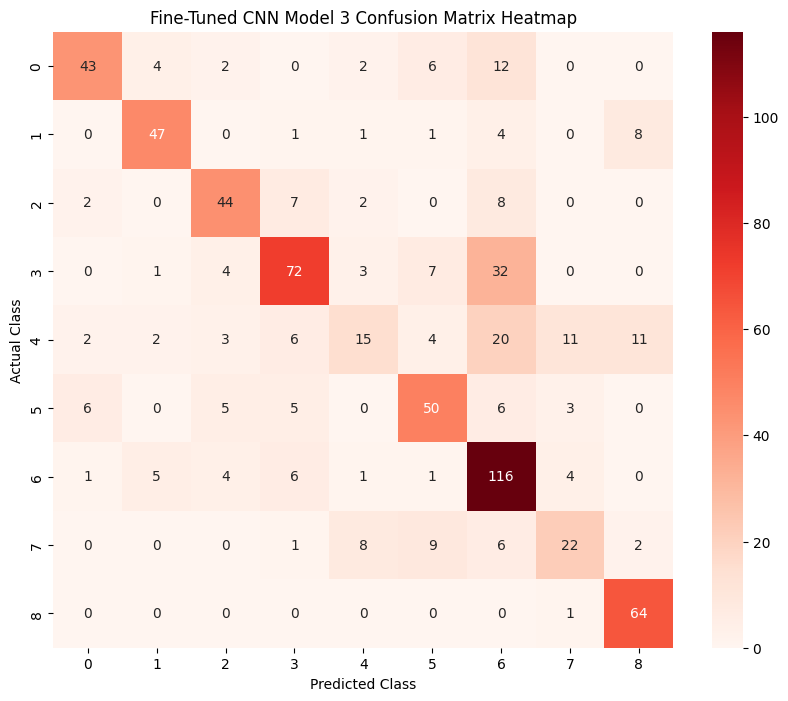

In [92]:
# Confusion Matrix heatmap on fine-tuned model 3 test result
cm3_fine = confusion_matrix(all_labels3_fine, all_predictions3_fine)

# Plot the confusion matrix as a heatmap with figsize 10 inches width wide and 8 inches tall height
plt.figure(figsize=(10, 8))

# Display prediction counts as integers in a red heatmap, with actual and predicted class labels from 0 to 8
sns.heatmap(cm3_fine, annot=True, fmt="d", cmap="Reds", xticklabels=range(9), yticklabels=range(9))
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Fine-Tuned CNN Model 3 Confusion Matrix Heatmap")
plt.show()

Output Explanation — Fine-Tuned CNN Model 3
Accuracy

**Accuracy: 66.62%** — Measures how often the CNN correctly predicts the waste category. The model correctly classified 475 out of 713 test images.

Classification Report

Precision

- **Precision (Class 0): 81%** — Of all images predicted as Class 0, 81% actually belonged to Class 0.
- **Precision (Class 1): 77%** — Of all images predicted as Class 1, 77% actually belonged to Class 1.
- **Precision (Class 2): 67%** — Of all images predicted as Class 2, 67% actually belonged to Class 2.
- **Precision (Class 3): 73%** — Of all images predicted as Class 3, 73% actually belonged to Class 3.
- **Precision (Class 4): 53%** — Of all images predicted as Class 4, 53% actually belonged to Class 4.
- **Precision (Class 5): 72%** — Of all images predicted as Class 5, 72% actually belonged to Class 5.
- **Precision (Class 6): 56%** — Of all images predicted as Class 6, 56% actually belonged to Class 6.
- **Precision (Class 7): 56%** — Of all images predicted as Class 7, 56% actually belonged to Class 7.
- **Precision (Class 8): 75%** — Of all images predicted as Class 8, 75% actually belonged to Class 8.

Recall

- **Class 0: 64%** — The model correctly identified 64% of all actual Class 0 images.
- **Class 1: 77%** — The model correctly identified 77% of all actual Class 1 images.
- **Class 2: 73%** — The model correctly identified 73% of all actual Class 2 images.
- **Class 3: 62%** — The model correctly identified 62% of all actual Class 3 images.
- **Class 4: 26%** — The model correctly identified 26% of all actual Class 4 images.
- **Class 5: 57%** — The model correctly identified 57% of all actual Class 5 images.
- **Class 6: 84%** — The model correctly identified 84% of all actual Class 6 images.
- **Class 7: 46%** — The model correctly identified 46% of all actual Class 7 images.
- **Class 8: 97%** — The model correctly identified 97% of all actual Class 8 images.

F1-score

- **Class 0: 0.72** — Combined measure of precision and recall.
- **Class 1: 0.77** — Combined measure of precision and recall.
- **Class 2: 0.70** — Combined measure of precision and recall.
- **Class 3: 0.67** — Combined measure of precision and recall.
- **Class 4: 0.35** — Combined measure of precision and recall.
- **Class 5: 0.64** — Combined measure of precision and recall.
- **Class 6: 0.67** — Combined measure of precision and recall.
- **Class 7: 0.51** — Combined measure of precision and recall.
- **Class 8: 0.85** — Combined measure of precision and recall.

- **Macro Average F1-score: 0.65** — Average F1-score across all nine classes, giving each class equal importance.
- **Weighted Average F1-score: 0.65** — Average F1-score across all nine classes, accounting for the number of actual images in each class.

Confusion Matrix

Each row represents the actual waste category, while each column represents the category predicted by the model. The diagonal values represent correct predictions.

- **Row 0:** [44, 5, 2, 0, 2, 5, 11, 0, 0] — 44 out of 69 Class 0 images were correctly predicted.
- **Row 1:** [0, 48, 0, 1, 1, 0, 4, 0, 8] — 48 out of 62 Class 1 images were correctly predicted.
- **Row 2:** [2, 0, 46, 6, 1, 0, 8, 0, 0] — 46 out of 63 Class 2 images were correctly predicted.
- **Row 3:** [0, 1, 4, 74, 4, 3, 33, 0, 0] — 74 out of 119 Class 3 images were correctly predicted.
- **Row 4:** [2, 2, 4, 7, 19, 2, 16, 11, 11] — 19 out of 74 Class 4 images were correctly predicted.
- **Row 5:** [5, 0, 7, 7, 2, 43, 10, 1, 0] — 43 out of 75 Class 5 images were correctly predicted.
- **Row 6:** [1, 5, 5, 5, 1, 1, 116, 4, 0] — 116 out of 138 Class 6 images were correctly predicted.
- **Row 7:** [0, 0, 1, 1, 6, 6, 10, 22, 2] — 22 out of 48 Class 7 images were correctly predicted.
- **Row 8:** [0, 1, 0, 0, 0, 0, 0, 1, 63] — 63 out of 65 Class 8 images were correctly predicted.

**Total:** 475 out of 713 test images were correctly classified, giving an accuracy of 66.62%.

-AUC (Receiver Operating Characteristic – Area Under the Curve)

**Multiclass ROC-AUC (OvR): 0.9319** — Measures how well the CNN distinguishes each waste category from the other eight categories using prediction probabilities.

A score of 0.9319 indicates strong class discrimination, although this does not mean the model has 93.19% classification accuracy.



Overall Evaluation

Fine-Tuned CNN Model 3 performed better than both the original and improved CNN Model 3.

Its accuracy increased from 51.89% (Original Model 3) and 63.25% (Improved Model 3) to 66.62%. Its macro F1-score increased from 0.48 and 0.61 to 0.65, while ROC-AUC increased from 0.8916 and 0.9221 to 0.9319.

Fine-tuning also reduced the best validation loss from 1.0949 to 0.9926.

The strongest class recognition was achieved for Vegetation (97% recall) and Plastic (84% recall). Miscellaneous Trash (26% recall) and Textile Trash (46% recall) remain challenging categories.

Compare CNN model 3 vs Improved CNN model 3 vs Improved Fine Tuned CNN model 3

In [93]:
# Store accuracy for all three models
accuracy3 = accuracy_score(all_labels3, all_predictions3)
accuracy3_impro = accuracy_score(all_labels3_impro, all_predictions3_impro)
accuracy3_fine = accuracy_score(all_labels3_fine, all_predictions3_fine)

# Store Model 3 classification report
report3 = classification_report(all_labels3, all_predictions3, output_dict=True)

# Store Improved Model 3 classification report
report3_impro = classification_report(all_labels3_impro, all_predictions3_impro, output_dict=True)

# Store Fine-Tuned Model 3 classification report
report3_fine = classification_report(all_labels3_fine, all_predictions3_fine, output_dict=True)

# Create a DataFrame to compare all three CNN models
# Weighted average: Calculates the overall precision, recall and F1-score while considering the number of test images in each class.

model_comparison3 = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],

    "CNN Model 3": [
        epoch_test3_loss,
        accuracy3,
        report3["weighted avg"]["precision"],
        report3["weighted avg"]["recall"],
        report3["weighted avg"]["f1-score"],
        roc_auc3
    ],

    "Improved CNN Model 3": [
        epoch_test3_impro_loss,
        accuracy3_impro,
        report3_impro["weighted avg"]["precision"],
        report3_impro["weighted avg"]["recall"],
        report3_impro["weighted avg"]["f1-score"],
        roc_auc3_impro
    ],

    "Fine-Tuned CNN Model 3": [
        epoch_test3_fine_loss,
        accuracy3_fine,
        report3_fine["weighted avg"]["precision"],
        report3_fine["weighted avg"]["recall"],
        report3_fine["weighted avg"]["f1-score"],
        roc_auc3_fine
    ]
})

model_comparison3

,Metric,CNN Model 3,Improved CNN Model 3,Fine-Tuned CNN Model 3
0,Test Loss,1.428427,1.089569,0.978640
1,Accuracy,0.518934,0.632539,0.663394
2,Precision,0.581936,0.636809,0.662559
3,Recall,0.518934,0.632539,0.663394
4,F1-Score,0.485419,0.614065,0.648672
5,ROC-AUC,0.891605,0.922105,0.933568


In [94]:
# Store confusion matrices for all three CNN models
cm3 = confusion_matrix(all_labels3, all_predictions3)
cm3_impro = confusion_matrix(all_labels3_impro, all_predictions3_impro)
cm3_fine = confusion_matrix(all_labels3_fine, all_predictions3_fine)

# Create a DataFrame to compare all three confusion matrices
confusion_comparison3 = pd.DataFrame({
    "Waste Category": [
        "Cardboard",
        "Food Organics",
        "Glass",
        "Metal",
        "Miscellaneous Trash",
        "Paper",
        "Plastic",
        "Textile Trash",
        "Vegetation"
    ],
    "CNN Model 3": [cm3[i, i] for i in range(9)], # Extract the number of correct predictions for each of the 9 waste categories from Model 3's confusion matrix diagonal
    "Improved CNN Model 3": [cm3_impro[i, i] for i in range(9)], # Extract the number of correct predictions for each of the 9 waste categories from Improved Model 3's confusion matrix diagonal.
    "Fine-Tuned CNN Model 3": [cm3_fine[i, i] for i in range(9)] # Extract the number of correct predictions for each of the 9 waste categories from Fine-Tuned Model 3's confusion matrix diagonal.
})

confusion_comparison3

,Waste Category,CNN Model 3,Improved CNN Model 3,Fine-Tuned CNN Model 3
0,Cardboard,48,45,43
1,Food Organics,30,47,47
2,Glass,52,44,44
3,Metal,98,64,72
4,Miscellaneous Trash,4,8,15
5,Paper,42,40,50
6,Plastic,42,118,116
7,Textile Trash,4,26,22
8,Vegetation,50,59,64


In [95]:
#lets wrap our final model into a varibale  called final model with short markdown
# Store the selected fine-tuned CNN Model 3 as the final model
final_model = cnn_model3

## 11. Real-Time Computer Vision and Waste Classification Using OpenCV


We will integrate our selected final_model with OpenCV to perform real-time waste image classification. We will capture images using a webcam, preprocess each captured image using the same transformations applied during model evaluation, and pass it to our trained CNN model to predict one of the nine waste categories. Finally, we will display the predicted category and its confidence score.

Firstly we bring our final_model to this section, create list of label class name ans create each function starting from Java then follow  by function where

OpenCV reads colour images in BGR order (Blue, Green, Red), whereas our PyTorch preprocessing expects RGB. We'll handle that conversion in the next step.

Then We must Convert the image from openCV BGR to our preprocessing pipeline method RGB PyTorch and also apply same transformation pipeline used for the whole dataset and model

We also need to find a way to add dataloader (batch size) logic because the CNN  model expects input in this format:

[batch_size, rgb, height, width]

Get the predictions and create another function to watermark any captured image with text of class and scores and percentage

**Bringing out the final model here**

In [96]:
# Save the selected fine-tuned CNN model weights
torch.save(final_model.state_dict(), FINAL_MODEL3_PATH)

print("Final model saved successfully!")
print("Model path:", FINAL_MODEL3_PATH)

Final model saved successfully!
Model path: /content/drive/MyDrive/Smart Waste Recognition AI/colab_models/final_cnn_model3.pth


In [97]:
# Load the saved final model weights ( confirming our saved final_model architecture)
final_model.load_state_dict(torch.load(FINAL_MODEL3_PATH, weights_only=True))

# Set the final model to evaluation mode
final_model.eval()

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): AdaptiveAvgPool2d(output_size=(1, 1))
  (13): Flatten(start_dim=1, end_dim=-1)
  (14): Dropout(p=0.3, inplace=False)
  (15): Linear(in_features=128, out_features=9, bias=True)


**Created List of Label Class**

In [98]:
# Import OpenCV, Computer Vision lib for real-time (image capture and processing)
import cv2

In [99]:
# Define waste category names corresponding to their numerical labels
# Define waste category names corresponding to their numerical labels

class_names = [
    "Cardboard",             # Label 0
    "Food Organics",         # Label 1
    "Glass",                 # Label 2
    "Metal",                 # Label 3
    "Miscellaneous Trash",   # Label 4
    "Paper",                 # Label 5
    "Plastic",               # Label 6
    "Textile Trash",         # Label 7
    "Vegetation"             # Label 8
]

In [100]:
# Import base64 for decoding webcam-image data into computer undertandingn (pthon bytes, pixels,rgb)
import base64

# Import display utilities for showing the webcam image in Colab and allow to use python coz of collab
from IPython.display import display, Javascript

This cell uses JavaScript to access the computer's webcam through the browser, capture a video frame and return the image to Google Colab for processing with Python and OpenCV.

We use JavaScript because Google Colab runs Python on a remote server, which cannot directly access the webcam connected to the local computer using cv2.VideoCapture(0).

In [101]:
# Import eval_js to execute JavaScript and return webcam image data to Python
from google.colab.output import eval_js

In [102]:
#cv2.VideoCapture() is an OpenCV function for accessing a video source and 0 tells OpenCV to use the default webcam.
# Access the computer's default webcam
cap = cv2.VideoCapture(0)

Create Javascript function to connect collab and computer webcam

In [103]:
# Create a reusable function to capture an image from the live webcam
def capture_webcam_image():

    # Capture an image from the live webcam
    js = Javascript("""
        async function captureFrame() {

            const video = document.createElement('video');

            const stream = await navigator.mediaDevices.getUserMedia({
                video: true
            });

            video.srcObject = stream;
            await video.play();

            document.body.appendChild(video);

            const button = document.createElement('button');
            button.textContent = 'Capture Image';
            document.body.appendChild(button);

            await new Promise(resolve => {
                button.onclick = resolve;
            });

            const canvas = document.createElement('canvas');

            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;

            canvas.getContext('2d').drawImage(
                video, 0, 0, canvas.width, canvas.height
            );

            const image = canvas.toDataURL('image/jpeg');

            stream.getTracks().forEach(track => track.stop());
            video.remove();
            button.remove();

            return image;
        }

        captureFrame();
    """)

    # Execute the JavaScript code and receive the captured image
    image_data = eval_js(js.data)

    # Return the captured image data
    return image_data

Create function to Save and decode  any captured image

In [104]:
def decode_and_save_image(image_data, image_name): # Create a reusable function to decode and save a captured webcam image

    project_folder = "/content/drive/MyDrive/Smart Waste Recognition AI" #Define the main project folder for o.s path below

    image_path = os.path.join(project_folder, image_name) #Define the complete image path so each predicted image saved automatically to project folder

    image_bytes = base64.b64decode(image_data.split(',')[1]) # Decode the Base64 image data into bytes (Removes the JPEG data URL prefix and keeps the encoded image.)

    image_array = np.frombuffer(image_bytes, dtype=np.uint8) # Convert the image bytes into a NumPy array (numpy 8 bit integer)

    captured_image = cv2.imdecode(image_array, cv2.IMREAD_COLOR) #Decode the NumPy array into an image using OpenCV (array turn to an image open cv understand)

    cv2.imwrite(image_path, captured_image) # Save the captured image directly to the main project folder using image_path

    print("Image saved to:", image_path) # Display the saved image location

    return captured_image # Return the captured OpenCV image


In [105]:
#This imports cv2_imshow, a display function provided by Google Colab.
from google.colab.patches import cv2_imshow

In [106]:
#cv2.cvtColor(): OpenCV function for converting an image from one colour space to another.
#cv2.COLOR_BGR2RGB: Specifies the conversion from BGR to RGB.

Create function to Preprocess and transform the captured image

In [107]:
def preprocess_webcam_image(captured_image): # Create a reusable function to preprocess a captured webcam image

    captured_image_rgb = cv2.cvtColor(captured_image, cv2.COLOR_BGR2RGB) # here we convert the captured image from BGR to RGB

    live_transform = images_transform(Image.fromarray(captured_image_rgb)) #Apply the same preprocessing the transformation pipeline we built for realwaste dataset (image_trasform) to var called live_transform, # if we ask for the image shape, we ger( we get 3 for rgb and 224 x 224 dimensiom in tensor)

    live_transform = live_transform.unsqueeze(0) #Add a batch dimension to the transformed image even tho the image is 1, unsqueeze(0) adds a new dimension at position 0, representing the batch size, e.g after shape, (We get 1 for batch size, 3 for rgb, 224 for height, 224 for width)

    return captured_image_rgb, live_transform # Return the RGB image and transformed tensor

Create function to Generate the prediction using final model

In [108]:
def predict_waste(live_transform): # Create a reusable function to generate predictions using the final CNN model

    with torch.no_grad(): # Disable gradient calculation because we are only making predictions

        live_outputs = final_model(live_transform) # Pass the transformed webcam image into the final CNN model

    print("Live output shape:", live_outputs.shape) # Display the model output shape e.g 1, 9 (1 = one captured image, 9 = one score logits for each of our nine waste categories.)

    print("Live logits:", live_outputs) #Display the raw model output (logits)

    live_probabilities = torch.softmax(live_outputs, dim=1) # Lets Convert the model outputs into probabilities using torch.softmax()

    live_predicted_index = torch.argmax(live_probabilities, dim=1).item() # Get the index of the class with the highest probability using argmax() and .item(), extract result from torch to python

    live_predicted_class = class_names[live_predicted_index] # Get the predicted waste category name

    live_confidence = live_probabilities.max(dim=1).values.item() * 100 #Get the highest prediction probability and turn it to a percentage (e.g 55.2%)

    return live_outputs, live_probabilities, live_predicted_index, live_predicted_class, live_confidence # Return the prediction results for resuseable

    return live_outputs # Return the model outputs for reuseable

Create Function to Display the prediction with its watermark

In [109]:
# Create a reusable function to display the captured image with prediction watermark %
def display_waste_prediction(captured_image_rgb, live_predicted_class, live_confidence):

    display_image = cv2.cvtColor(captured_image_rgb, cv2.COLOR_RGB2BGR) # Convert the captured RGB image into BGR for OpenCV display

    prediction_label = f"{live_predicted_class}: {live_confidence:.2f}%" # Create the prediction label with the waste category and confidence score

    cv2.putText( # put the marker text on the image like this,
        display_image, # show image first using var display_image,
        prediction_label, # show the class name and score % on it using var prediction_label
        (20, 40), # Places both the text class and score 20 pixels from the left and 40 pixels from the top.
        cv2.FONT_HERSHEY_SIMPLEX, # Selects OpenCV's  hershey Simplex font.
        1,                    # Sets the font size to 1.
        (0, 0, 255),          #Red in BGR colour orde
        2                     #Makes the text 2 pixels thick.
    )

    # Display the image with its prediction
    cv2_imshow(display_image)

    # Return the labelled image
    return display_image

## 12. Live Capture Experiment


Live Capturing and decoding

Image saved to: /content/drive/MyDrive/Smart Waste Recognition AI/live_captured.jpg


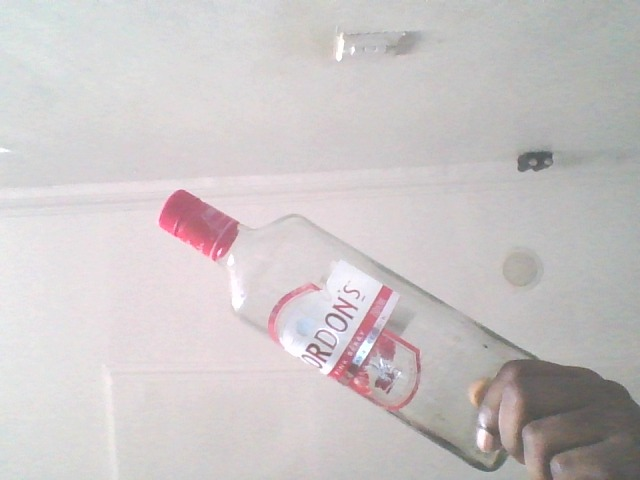

In [212]:
image_data = capture_webcam_image() # we bring the javascript function here to open camera and capture

captured_image = decode_and_save_image( image_data,"live_captured.jpg") # Decode and save the capture  waste image

cv2_imshow(captured_image) # Display the captured image using cv2_imshow

Preprocess and transform

In [214]:
captured_image_rgb, live_transform = preprocess_webcam_image(captured_image) #Preprocess the captured webcam image using the func captured_image_rgb, live_transform

print("Live transform shape:", live_transform.shape) #Display the transformed image shape


Live transform shape: torch.Size([1, 3, 224, 224])


Preditions and probabilities result

In [215]:
live_outputs, live_probabilities, live_predicted_index, live_predicted_class, live_confidence = predict_waste(live_transform)## Generate the waste prediction using the final CNN model wole funcs created

print("Predicted class index:", live_predicted_index) # Display the predicted class index

print("Predicted class name:", live_predicted_class) # Display the predicted waste class or category

print("Prediction confidence:", f"{live_confidence:.2f}%") #Display the prediction confidence

Live output shape: torch.Size([1, 9])
Live logits: tensor([[  6.3990, -16.8122,  -7.6474,  -0.4048,  -0.5024,   5.7728,  -3.2610,
           3.7382, -13.1277]])
Predicted class index: 0
Predicted class name: Cardboard
Prediction confidence: 62.24%


Watermark and save to folder path

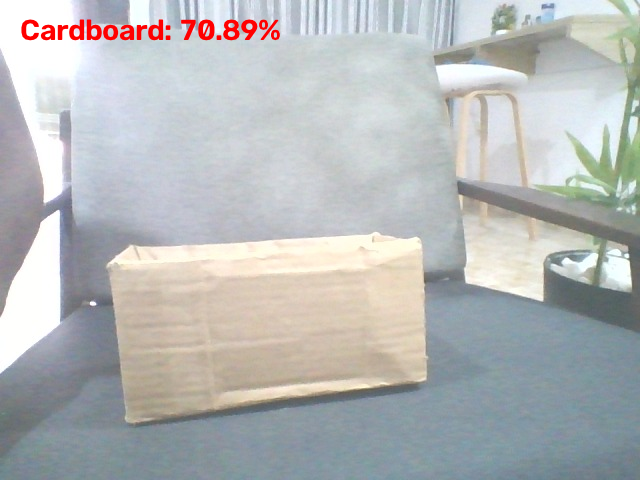

Prediction image saved: True


In [195]:
display_image = display_waste_prediction(captured_image_rgb, live_predicted_class, live_confidence) #Display the captured image with its prediction label

project_folder = "/content/drive/MyDrive/Smart Waste Recognition AI" # Define the main project folder

live_image_path = os.path.join(project_folder, "plastic_prediction.jpg") # Define the prediction image path

cv2.imwrite(live_image_path, display_image) # Save the image with its prediction label

print("Prediction image saved:", os.path.exists(live_image_path)) # Confirm that the prediction image was saved

## 13. Deployment

Preparing the final trained model for deployment, building and testing a Streamlit web application, deploying the application using Hugging Face Spaces, documenting the project, and publishing the complete project to GitHub.

In [ ]:
# Import shutil for copying files
import shutil

import os

In [ ]:
# Define the deployment folder
deployment_folder = "/content/drive/MyDrive/Smart Waste Recognition AI/deployment"

# Create the deployment folder
os.makedirs(deployment_folder, exist_ok=True)

# Confirm that the deployment folder exists
print("Deployment folder created:", os.path.exists(deployment_folder))

Deployment folder created: True


In [ ]:
# Define the main project folder
project_folder = "/content/drive/MyDrive/Smart Waste Recognition AI"

# Define the source model path
source_model = os.path.join(project_folder,"colab_models","final_cnn_model3.pth")

# Define the destination model path
deployment_model = os.path.join( deployment_folder,"final_cnn_model3.pth")

# Copy the final trained model into the deployment folder
shutil.copy2(source_model, deployment_model)

# Confirm that the model was copied successfully
print("Model copied:", os.path.exists(deployment_model))

Model copied: True


In [ ]:
# List the files inside the deployment folder
print(os.listdir(deployment_folder))

['final_cnn_model3.pth']
